In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
PROJECT_ROOT = Path("..")

TRAIN_PATH = PROJECT_ROOT / "data" / "raw" / "transactions_train.csv"
TEST_PATH = PROJECT_ROOT / "data" / "raw" / "transactions_test.csv"

print("Train path:", TRAIN_PATH)
print("Test path :", TEST_PATH)

Train path: ..\data\raw\transactions_train.csv
Test path : ..\data\raw\transactions_test.csv


In [3]:
print("Train file exists:", TRAIN_PATH.exists())
print("Test file exists :", TEST_PATH.exists())

Train file exists: True
Test file exists : True


In [4]:
train_df = pd.read_csv(TRAIN_PATH)

print("Training dataset loaded successfully.")

Training dataset loaded successfully.


In [5]:
test_df = pd.read_csv(TEST_PATH)

print("Test dataset loaded successfully.")

Test dataset loaded successfully.


In [6]:
print("Training Dataset Shape:")
print(train_df.shape)

print("\nTest Dataset Shape:")
print(test_df.shape)

Training Dataset Shape:
(300113, 21)

Test Dataset Shape:
(99887, 21)


In [7]:
train_df.head()

,transaction_id,transaction_time,customer_id,merchant_id,account_age_days,credit_score_band,kyc_level,avg_monthly_spend,merchant_risk_score,transaction_amount,payment_channel,device_type,is_international,ip_risk_score,txn_count_1h,txn_count_24h,failed_txn_count_24h,geo_distance_from_last_txn,amount_deviation_from_user_mean,is_fraud,post_auth_risk_score
0,359131,2023-01-01 00:02:00.328105993,11102,2282,284,2,3,6091.747132,0.456269,2408.320473,wallet,desktop,0,0.142532,1,3,1,33.458018,2205.262235,0,0.099920
1,351207,2023-01-01 00:02:26.339769237,22891,3016,1363,2,3,3794.044563,0.449021,2765.255095,bank_transfer,mobile,0,0.131811,0,5,0,3.375083,2638.786943,0,0.291715
2,10209,2023-01-01 00:06:54.145825305,3102,1855,1318,5,2,6697.058451,0.220252,1529.079168,card,desktop,0,0.322137,0,5,0,13.732603,1305.843886,0,0.216647
3,62660,2023-01-01 00:06:57.723185583,4041,2525,1914,1,1,2906.711704,0.202223,610.407487,card,mobile,0,0.171764,1,2,0,18.840187,513.517097,0,0.354154
4,384254,2023-01-01 00:08:05.487541188,3979,1555,360,2,3,5082.651983,0.171230,986.397163,card,mobile,0,0.248766,1,1,0,15.344375,816.975430,0,0.149084


In [8]:
train_df.tail()

,transaction_id,transaction_time,customer_id,merchant_id,account_age_days,credit_score_band,kyc_level,avg_monthly_spend,merchant_risk_score,transaction_amount,payment_channel,device_type,is_international,ip_risk_score,txn_count_1h,txn_count_24h,failed_txn_count_24h,geo_distance_from_last_txn,amount_deviation_from_user_mean,is_fraud,post_auth_risk_score
300108,616,2023-09-30 23:51:22.274649025,8617,514,534,3,3,941.764000,0.160330,727.772268,bank_transfer,tablet,0,0.291943,0,5,0,10.946445,696.380135,0,0.279189
300109,170218,2023-09-30 23:51:36.040130562,770,4385,1799,2,3,7755.027311,0.073381,1255.679679,card,mobile,0,0.678220,1,3,0,81.351694,997.178769,0,0.128350
300110,280461,2023-09-30 23:53:48.594046447,9024,3356,1604,3,1,4283.249768,0.259514,3749.538468,card,mobile,0,0.240876,1,0,1,7.557995,3606.763476,0,0.335726
300111,272825,2023-09-30 23:56:23.912430794,18637,1306,1376,4,1,1974.282381,0.161716,6865.922315,card,desktop,0,0.588353,1,3,0,69.399084,6800.112902,0,0.234647
300112,296909,2023-09-30 23:56:57.561687899,18112,242,506,4,3,1929.724124,0.307236,2459.019586,card,mobile,0,0.187646,0,2,0,81.797284,2394.695449,0,0.079394


In [9]:
train_df.sample(10, random_state=42)

,transaction_id,transaction_time,customer_id,merchant_id,account_age_days,credit_score_band,kyc_level,avg_monthly_spend,merchant_risk_score,transaction_amount,payment_channel,device_type,is_international,ip_risk_score,txn_count_1h,txn_count_24h,failed_txn_count_24h,geo_distance_from_last_txn,amount_deviation_from_user_mean,is_fraud,post_auth_risk_score
71657,92911,2023-03-07 01:58:07.713930702,1997,5229,1855,4,2,4031.845122,0.031227,610.397262,wallet,mobile,1,0.330495,0,4,0,13.752286,476.002425,0,0.260961
31954,67672,2023-01-30 06:31:15.153490393,30716,1380,1375,1,1,3078.233976,0.204899,371.197582,card,desktop,0,0.240097,2,2,0,20.929682,268.589783,0,0.262389
122888,245330,2023-04-22 14:50:53.082758401,39144,6495,1635,5,3,7772.126191,0.118606,1727.976172,card,desktop,0,0.721067,1,4,0,5.116875,1468.905299,0,0.270070
81423,166049,2023-03-15 23:28:53.428269115,22667,1642,1598,4,3,7007.655267,0.301859,1998.895638,upi,mobile,0,0.490227,1,2,1,23.842876,1765.307129,0,0.320794
177516,323289,2023-06-11 07:48:50.536380886,6074,6014,1912,4,3,607.701068,0.508737,2430.777939,card,mobile,0,0.163740,2,1,1,6.880675,2410.521237,0,0.012356
269153,181606,2023-09-02 18:19:12.795445113,14460,2732,811,5,2,5059.341986,0.251888,1830.710528,card,mobile,0,0.311567,2,6,1,79.830804,1662.065795,0,0.032117
212152,318034,2023-07-13 00:03:07.169337615,23284,6641,702,5,3,4944.124199,0.290893,526.139718,card,mobile,0,0.273847,1,5,0,8.288426,361.335578,0,0.112474
284224,145174,2023-09-16 14:25:24.303236071,25068,7389,551,3,3,3453.715394,0.517823,1673.238430,card,desktop,1,0.277212,1,7,1,15.126113,1558.114583,0,0.109977
70654,82384,2023-03-06 02:59:31.425561845,37493,7340,1275,5,3,8022.394917,0.253773,939.170891,wallet,desktop,0,0.049340,2,6,1,37.196691,671.757727,0,0.334486
180437,114392,2023-06-14 00:36:09.036375341,3231,1962,620,1,1,3522.848147,0.332364,4638.373380,upi,mobile,0,0.184297,0,3,0,21.312277,4520.945108,0,0.241938


In [10]:
print("Number of columns:", len(train_df.columns))

print("\nColumn Names:")
for i, column in enumerate(train_df.columns, start=1):
    print(f"{i}. {column}")

Number of columns: 21

Column Names:
1. transaction_id
2. transaction_time
3. customer_id
4. merchant_id
5. account_age_days
6. credit_score_band
7. kyc_level
8. avg_monthly_spend
9. merchant_risk_score
10. transaction_amount
11. payment_channel
12. device_type
13. is_international
14. ip_risk_score
15. txn_count_1h
16. txn_count_24h
17. failed_txn_count_24h
18. geo_distance_from_last_txn
19. amount_deviation_from_user_mean
20. is_fraud
21. post_auth_risk_score


In [11]:
train_df.dtypes

transaction_id                       int64
transaction_time                    object
customer_id                          int64
merchant_id                          int64
account_age_days                     int64
credit_score_band                    int64
kyc_level                            int64
avg_monthly_spend                  float64
merchant_risk_score                float64
transaction_amount                 float64
payment_channel                     object
device_type                         object
is_international                     int64
ip_risk_score                      float64
txn_count_1h                         int64
txn_count_24h                        int64
failed_txn_count_24h                 int64
geo_distance_from_last_txn         float64
amount_deviation_from_user_mean    float64
is_fraud                             int64
post_auth_risk_score               float64
dtype: object

In [12]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300113 entries, 0 to 300112
Data columns (total 21 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   transaction_id                   300113 non-null  int64  
 1   transaction_time                 300113 non-null  object 
 2   customer_id                      300113 non-null  int64  
 3   merchant_id                      300113 non-null  int64  
 4   account_age_days                 300113 non-null  int64  
 5   credit_score_band                300113 non-null  int64  
 6   kyc_level                        300113 non-null  int64  
 7   avg_monthly_spend                300113 non-null  float64
 8   merchant_risk_score              300113 non-null  float64
 9   transaction_amount               300113 non-null  float64
 10  payment_channel                  300113 non-null  object 
 11  device_type                      300113 non-null  object 
 12  is

In [13]:
train_df.describe()

,transaction_id,customer_id,merchant_id,account_age_days,credit_score_band,kyc_level,avg_monthly_spend,merchant_risk_score,transaction_amount,is_international,ip_risk_score,txn_count_1h,txn_count_24h,failed_txn_count_24h,geo_distance_from_last_txn,amount_deviation_from_user_mean,is_fraud,post_auth_risk_score
count,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000
mean,200077.191185,19981.583673,3995.485907,1017.180785,3.003006,1.999424,4985.739577,0.251409,2402.123927,0.069151,0.285698,1.100296,3.201854,0.350558,34.180513,2235.932608,0.016231,0.210904
std,115496.679985,11542.118118,2307.565404,572.015824,1.409776,0.817830,3147.609178,0.146557,1699.365704,0.253711,0.160172,1.048071,1.788689,0.592392,25.702402,1702.430669,0.126361,0.141454
min,1.000000,0.000000,0.000000,30.000000,1.000000,1.000000,43.855387,0.001365,4.311496,0.000000,0.000345,0.000000,0.000000,0.000000,0.000209,-778.603491,0.000000,0.000001
25%,100008.000000,9993.000000,1995.000000,520.000000,2.000000,1.000000,2690.068001,0.135988,1152.938608,0.000000,0.160787,0.000000,2.000000,0.000000,13.695516,987.692303,0.000000,0.102204
50%,199977.000000,19978.000000,3997.000000,1018.000000,3.000000,2.000000,4334.611451,0.229556,2017.180129,0.000000,0.264349,1.000000,3.000000,0.000000,28.916764,1853.581813,0.000000,0.203781
75%,300147.000000,29976.000000,5992.000000,1515.000000,4.000000,3.000000,6607.227191,0.345529,3230.321544,0.000000,0.389043,2.000000,4.000000,1.000000,49.368702,3067.286174,0.000000,0.305352
max,399997.000000,39999.000000,7999.000000,1999.000000,5.000000,3.000000,32362.617533,0.837624,19486.987108,1.000000,0.964121,9.000000,15.000000,5.000000,199.135624,19419.022461,1.000000,0.999861


In [14]:
train_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,300113.0,NaN,NaN,NaN,200077.191185,115496.679985,1.0,100008.0,199977.0,300147.0,399997.0
transaction_time,300113,300113,2023-01-01 00:02:00.328105993,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,300113.0,NaN,NaN,NaN,19981.583673,11542.118118,0.0,9993.0,19978.0,29976.0,39999.0
merchant_id,300113.0,NaN,NaN,NaN,3995.485907,2307.565404,0.0,1995.0,3997.0,5992.0,7999.0
account_age_days,300113.0,NaN,NaN,NaN,1017.180785,572.015824,30.0,520.0,1018.0,1515.0,1999.0
credit_score_band,300113.0,NaN,NaN,NaN,3.003006,1.409776,1.0,2.0,3.0,4.0,5.0
kyc_level,300113.0,NaN,NaN,NaN,1.999424,0.81783,1.0,1.0,2.0,3.0,3.0
avg_monthly_spend,300113.0,NaN,NaN,NaN,4985.739577,3147.609178,43.855387,2690.068001,4334.611451,6607.227191,32362.617533
merchant_risk_score,300113.0,NaN,NaN,NaN,0.251409,0.146557,0.001365,0.135988,0.229556,0.345529,0.837624
transaction_amount,300113.0,NaN,NaN,NaN,2402.123927,1699.365704,4.311496,1152.938608,2017.180129,3230.321544,19486.987108


In [15]:
missing_values = train_df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

missing_values

Series([], dtype: int64)

In [16]:
missing_percentage = (train_df.isnull().sum() / len(train_df)) * 100

missing_percentage = (
    missing_percentage[missing_percentage > 0]
    .sort_values(ascending=False)
)

missing_percentage

Series([], dtype: float64)

In [17]:
duplicate_count = train_df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [18]:
numerical_columns = train_df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = train_df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['transaction_id', 'customer_id', 'merchant_id', 'account_age_days', 'credit_score_band', 'kyc_level', 'avg_monthly_spend', 'merchant_risk_score', 'transaction_amount', 'is_international', 'ip_risk_score', 'txn_count_1h', 'txn_count_24h', 'failed_txn_count_24h', 'geo_distance_from_last_txn', 'amount_deviation_from_user_mean', 'is_fraud', 'post_auth_risk_score']

Categorical columns:
['transaction_time', 'payment_channel', 'device_type']


In [19]:
unique_counts = train_df.nunique().sort_values(ascending=False)

unique_counts

transaction_id                     300113
transaction_time                   300113
transaction_amount                 300102
amount_deviation_from_user_mean    300100
geo_distance_from_last_txn         299528
ip_risk_score                      232786
post_auth_risk_score               213701
customer_id                         39983
avg_monthly_spend                   39983
merchant_id                          8000
merchant_risk_score                  7941
account_age_days                     1970
txn_count_24h                          15
txn_count_1h                           10
failed_txn_count_24h                    6
credit_score_band                       5
payment_channel                         4
kyc_level                               3
device_type                             3
is_international                        2
is_fraud                                2
dtype: int64

In [20]:
fraud_columns = [
    column for column in train_df.columns
    if any(keyword in column.lower() for keyword in [
        "fraud",
        "is_fraud",
        "label",
        "target"
    ])
]

print("Potential target columns:")
print(fraud_columns)

Potential target columns:
['is_fraud']


In [21]:
target_column = "is_fraud"

print(train_df[target_column].value_counts())

is_fraud
0    295242
1      4871
Name: count, dtype: int64


In [22]:
target_distribution = train_df[target_column].value_counts()

fraud_percentage = (
    target_distribution.get(1, 0) / len(train_df)
) * 100

print(f"Fraud percentage: {fraud_percentage:.2f}%")

Fraud percentage: 1.62%


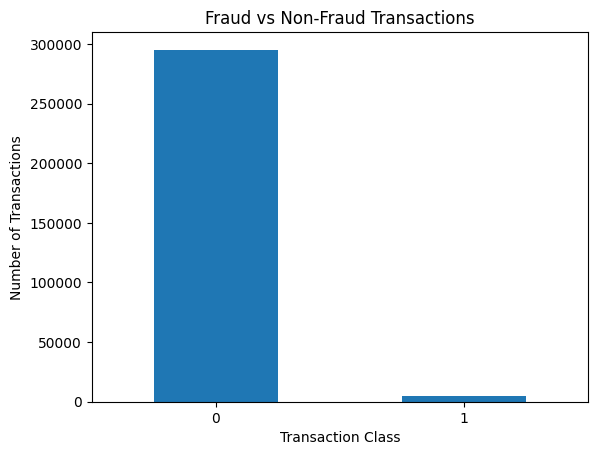

In [23]:
train_df[target_column].value_counts().plot(
    kind="bar"
)

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

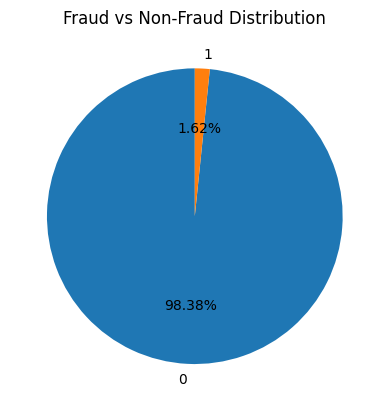

In [24]:
train_df[target_column].value_counts().plot(
    kind="pie",
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Fraud vs Non-Fraud Distribution")
plt.ylabel("")

plt.show()

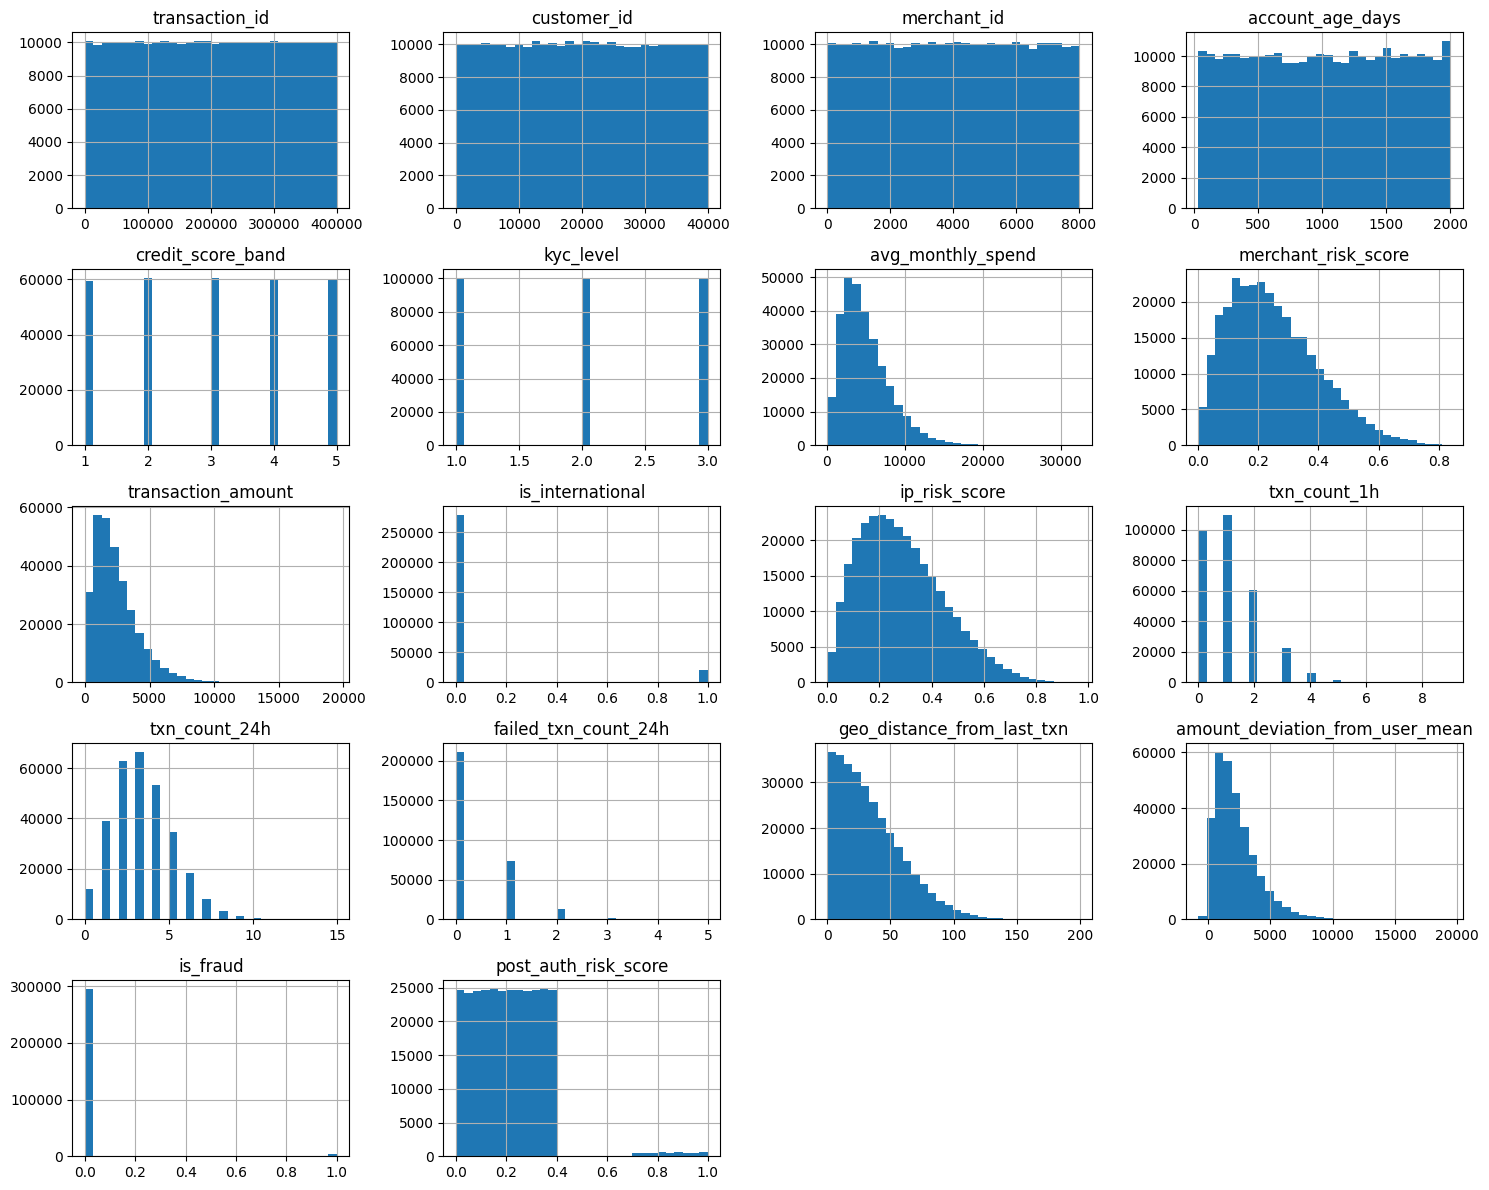

In [25]:
train_df[numerical_columns].hist(
    figsize=(15, 12),
    bins=30
)

plt.tight_layout()
plt.show()

In [26]:
for column in categorical_columns:
    print(f"\n{'=' * 60}")
    print(f"Column: {column}")
    print(f"Unique values: {train_df[column].nunique()}")
    print(train_df[column].value_counts().head(10))


Column: transaction_time
Unique values: 300113
transaction_time
2023-01-01 00:02:00.328105993    1
2023-01-01 00:02:26.339769237    1
2023-01-01 00:06:54.145825305    1
2023-01-01 00:06:57.723185583    1
2023-01-01 00:08:05.487541188    1
2023-01-01 00:09:11.294695623    1
2023-01-01 00:10:05.075100599    1
2023-01-01 00:11:53.896526457    1
2023-01-01 00:13:23.350519980    1
2023-01-01 00:13:31.431162139    1
Name: count, dtype: int64

Column: payment_channel
Unique values: 4
payment_channel
card             149765
upi               75108
wallet            45176
bank_transfer     30064
Name: count, dtype: int64

Column: device_type
Unique values: 3
device_type
mobile     210051
desktop     75080
tablet      14982
Name: count, dtype: int64


In [27]:
for column in categorical_columns:
    if train_df[column].nunique() <= 20:
        
        fraud_rate = train_df.groupby(column)[target_column].mean() * 100
        
        print(f"\nFraud Rate by {column}:")
        print(fraud_rate.sort_values(ascending=False))


Fraud Rate by payment_channel:
payment_channel
card             1.643909
upi              1.625659
bank_transfer    1.589941
wallet           1.571631
Name: is_fraud, dtype: float64

Fraud Rate by device_type:
device_type
mobile     1.627700
desktop    1.620938
tablet     1.568549
Name: is_fraud, dtype: float64


In [28]:
correlation = train_df[numerical_columns].corr()[target_column]

correlation = correlation.sort_values(
    ascending=False
)

correlation

is_fraud                           1.000000
post_auth_risk_score               0.581935
txn_count_24h                      0.196955
failed_txn_count_24h               0.074802
is_international                   0.038266
merchant_risk_score                0.014890
ip_risk_score                      0.012986
txn_count_1h                       0.007660
kyc_level                          0.002638
geo_distance_from_last_txn         0.002035
customer_id                        0.000408
credit_score_band                  0.000381
account_age_days                  -0.000693
merchant_id                       -0.001141
transaction_id                    -0.001510
avg_monthly_spend                 -0.002534
amount_deviation_from_user_mean   -0.006925
transaction_amount                -0.007094
Name: is_fraud, dtype: float64

In [29]:
top_correlations = correlation.abs().sort_values(
    ascending=False
).head(15)

top_correlations

is_fraud                           1.000000
post_auth_risk_score               0.581935
txn_count_24h                      0.196955
failed_txn_count_24h               0.074802
is_international                   0.038266
merchant_risk_score                0.014890
ip_risk_score                      0.012986
txn_count_1h                       0.007660
transaction_amount                 0.007094
amount_deviation_from_user_mean    0.006925
kyc_level                          0.002638
avg_monthly_spend                  0.002534
geo_distance_from_last_txn         0.002035
transaction_id                     0.001510
merchant_id                        0.001141
Name: is_fraud, dtype: float64

In [30]:
memory_usage = train_df.memory_usage(deep=True).sum()

memory_mb = memory_usage / (1024 ** 2)

print(f"Dataset memory usage: {memory_mb:.2f} MB")

Dataset memory usage: 94.79 MB


In [31]:
summary = pd.DataFrame({
    "Metric": [
        "Number of Rows",
        "Number of Columns",
        "Duplicate Rows",
        "Missing Values",
        "Numerical Columns",
        "Categorical Columns",
        "Memory Usage (MB)"
    ],
    "Value": [
        train_df.shape[0],
        train_df.shape[1],
        train_df.duplicated().sum(),
        train_df.isnull().sum().sum(),
        len(numerical_columns),
        len(categorical_columns),
        round(memory_mb, 2)
    ]
})

summary

,Metric,Value
0,Number of Rows,300113.00
1,Number of Columns,21.00
2,Duplicate Rows,0.00
3,Missing Values,0.00
4,Numerical Columns,18.00
5,Categorical Columns,3.00
6,Memory Usage (MB),94.79


In [32]:
categorical_columns = [
    "payment_channel",
    "device_type",
    "credit_score_band",
    "kyc_level",
    "is_international"
]

for column in categorical_columns:
    print(f"\n{'=' * 60}")
    print(f"Column: {column}")
    print(f"{'=' * 60}")
    print(train_df[column].value_counts())


Column: payment_channel
payment_channel
card             149765
upi               75108
wallet            45176
bank_transfer     30064
Name: count, dtype: int64

Column: device_type
device_type
mobile     210051
desktop     75080
tablet      14982
Name: count, dtype: int64

Column: credit_score_band
credit_score_band
3    60536
2    60377
4    60237
5    59742
1    59221
Name: count, dtype: int64

Column: kyc_level
kyc_level
1    100451
3    100278
2     99384
Name: count, dtype: int64

Column: is_international
is_international
0    279360
1     20753
Name: count, dtype: int64


In [33]:
for column in categorical_columns:

    fraud_rate = (
        train_df.groupby(column)["is_fraud"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print(f"\n{'=' * 60}")
    print(f"Fraud Rate by {column}")
    print(f"{'=' * 60}")
    
    print(fraud_rate)


Fraud Rate by payment_channel
payment_channel
card             1.643909
upi              1.625659
bank_transfer    1.589941
wallet           1.571631
Name: is_fraud, dtype: float64

Fraud Rate by device_type
device_type
mobile     1.627700
desktop    1.620938
tablet     1.568549
Name: is_fraud, dtype: float64

Fraud Rate by credit_score_band
credit_score_band
4    1.668410
3    1.648606
1    1.607538
2    1.599947
5    1.590171
Name: is_fraud, dtype: float64

Fraud Rate by kyc_level
kyc_level
3    1.657392
2    1.636078
1    1.575893
Name: is_fraud, dtype: float64

Fraud Rate by is_international
is_international
1    3.397099
0    1.491266
Name: is_fraud, dtype: float64


In [34]:
for column in categorical_columns:

    fraud_count = (
        train_df.groupby(column)["is_fraud"]
        .sum()
        .sort_values(ascending=False)
    )

    print(f"\n{'=' * 60}")
    print(f"Fraud Count by {column}")
    print(f"{'=' * 60}")
    
    print(fraud_count)


Fraud Count by payment_channel
payment_channel
card             2462
upi              1221
wallet            710
bank_transfer     478
Name: is_fraud, dtype: int64

Fraud Count by device_type
device_type
mobile     3419
desktop    1217
tablet      235
Name: is_fraud, dtype: int64

Fraud Count by credit_score_band
credit_score_band
4    1005
3     998
2     966
1     952
5     950
Name: is_fraud, dtype: int64

Fraud Count by kyc_level
kyc_level
3    1662
2    1626
1    1583
Name: is_fraud, dtype: int64

Fraud Count by is_international
is_international
0    4166
1     705
Name: is_fraud, dtype: int64


In [35]:
numerical_features = [
    "account_age_days",
    "avg_monthly_spend",
    "merchant_risk_score",
    "transaction_amount",
    "ip_risk_score",
    "txn_count_1h",
    "txn_count_24h",
    "failed_txn_count_24h",
    "geo_distance_from_last_txn",
    "amount_deviation_from_user_mean",
    "post_auth_risk_score"
]

fraud_comparison = train_df.groupby("is_fraud")[numerical_features].mean().T

fraud_comparison

is_fraud,0,1
account_age_days,1017.231668,1014.096695
avg_monthly_spend,4986.763890,4923.653715
merchant_risk_score,0.251129,0.268398
transaction_amount,2403.672280,2308.274852
ip_risk_score,0.285431,0.301891
txn_count_1h,1.099264,1.162800
txn_count_24h,3.156604,5.944570
failed_txn_count_24h,0.344866,0.695545
geo_distance_from_last_txn,34.173795,34.587663
amount_deviation_from_user_mean,2237.446817,2144.153061


In [36]:
fraud_median_comparison = (
    train_df.groupby("is_fraud")[numerical_features]
    .median()
    .T
)

fraud_median_comparison

is_fraud,0,1
account_age_days,1018.000000,1017.000000
avg_monthly_spend,4335.533822,4280.824216
merchant_risk_score,0.229110,0.246434
transaction_amount,2018.390038,1928.837440
ip_risk_score,0.264100,0.277421
txn_count_1h,1.000000,1.000000
txn_count_24h,3.000000,6.000000
failed_txn_count_24h,0.000000,0.000000
geo_distance_from_last_txn,28.914804,28.984256
amount_deviation_from_user_mean,1854.905497,1757.848836


In [37]:
velocity_analysis = (
    train_df.groupby("txn_count_24h")["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

velocity_analysis["fraud_rate"] *= 100

velocity_analysis

,transaction_count,fraud_count,fraud_rate
txn_count_24h,,,
0,12136,68,0.560316
1,39177,194,0.495189
2,62767,330,0.525754
3,66494,407,0.612085
4,53440,455,0.851422
5,34471,548,1.589742
6,18332,656,3.578442
7,8147,689,8.457101
8,3475,695,20.000000


In [38]:
velocity_1h_analysis = (
    train_df.groupby("txn_count_1h")["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

velocity_1h_analysis["fraud_rate"] *= 100

velocity_1h_analysis

,transaction_count,fraud_count,fraud_rate
txn_count_1h,,,
0,99897,1562,1.563611
1,109738,1753,1.597441
2,60577,1020,1.683807
3,22164,321,1.448295
4,6176,176,2.849741
5,1287,30,2.331002
6,235,9,3.829787
7,33,0,0.000000
8,5,0,0.000000


In [39]:
failed_txn_analysis = (
    train_df.groupby("failed_txn_count_24h")["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

failed_txn_analysis["fraud_rate"] *= 100

failed_txn_analysis

,transaction_count,fraud_count,fraud_rate
failed_txn_count_24h,,,
0,211486,2471,1.168399
1,73830,1613,2.184749
2,13139,616,4.688332
3,1541,145,9.409474
4,109,22,20.183486
5,8,4,50.000000


In [40]:
international_analysis = (
    train_df.groupby("is_international")["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

international_analysis["fraud_rate"] *= 100

international_analysis

,transaction_count,fraud_count,fraud_rate
is_international,,,
0,279360,4166,1.491266
1,20753,705,3.397099


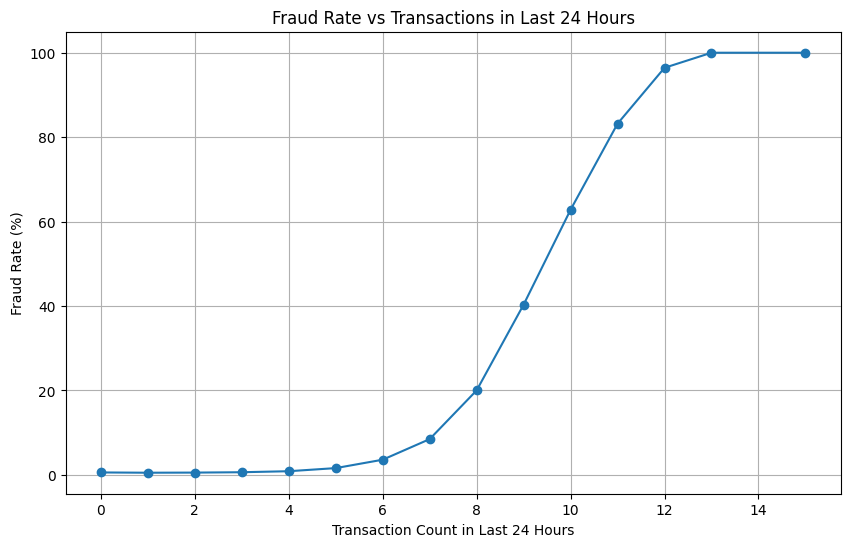

In [41]:
plt.figure(figsize=(10, 6))

plt.plot(
    velocity_analysis.index,
    velocity_analysis["fraud_rate"],
    marker="o"
)

plt.title("Fraud Rate vs Transactions in Last 24 Hours")
plt.xlabel("Transaction Count in Last 24 Hours")
plt.ylabel("Fraud Rate (%)")
plt.grid(True)

plt.show()

In [42]:
train_df["transaction_time"] = pd.to_datetime(
    train_df["transaction_time"]
)

test_df["transaction_time"] = pd.to_datetime(
    test_df["transaction_time"]
)

print(train_df["transaction_time"].dtype)

datetime64[ns]


In [43]:
train_df["hour"] = train_df["transaction_time"].dt.hour
train_df["day_of_week"] = train_df["transaction_time"].dt.dayofweek
train_df["day"] = train_df["transaction_time"].dt.day
train_df["month"] = train_df["transaction_time"].dt.month
train_df["is_weekend"] = (
    train_df["day_of_week"] >= 5
).astype(int)

train_df[
    [
        "transaction_time",
        "hour",
        "day_of_week",
        "day",
        "month",
        "is_weekend"
    ]
].head()

,transaction_time,hour,day_of_week,day,month,is_weekend
0,2023-01-01 00:02:00.328105993,0,6,1,1,1
1,2023-01-01 00:02:26.339769237,0,6,1,1,1
2,2023-01-01 00:06:54.145825305,0,6,1,1,1
3,2023-01-01 00:06:57.723185583,0,6,1,1,1
4,2023-01-01 00:08:05.487541188,0,6,1,1,1


In [44]:
hourly_fraud = (
    train_df.groupby("hour")["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

hourly_fraud["fraud_rate"] *= 100

hourly_fraud

,transaction_count,fraud_count,fraud_rate
hour,,,
0,12462,167,1.340074
1,12705,202,1.589925
2,12557,218,1.736083
3,12610,181,1.435369
4,12452,206,1.654353
5,12437,211,1.696551
6,12664,214,1.689829
7,12468,208,1.668271
8,12455,192,1.541550


In [45]:
weekly_fraud = (
    train_df.groupby("day_of_week")["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

weekly_fraud["fraud_rate"] *= 100

weekly_fraud

,transaction_count,fraud_count,fraud_rate
day_of_week,,,
0,42721,682,1.596405
1,42958,661,1.538712
2,42962,697,1.622364
3,43267,680,1.571637
4,42690,708,1.658468
5,42635,744,1.745045
6,42880,699,1.630131


In [46]:
weekend_fraud = (
    train_df.groupby("is_weekend")["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

weekend_fraud["fraud_rate"] *= 100

weekend_fraud

,transaction_count,fraud_count,fraud_rate
is_weekend,,,
0,214598,3428,1.597405
1,85515,1443,1.687423


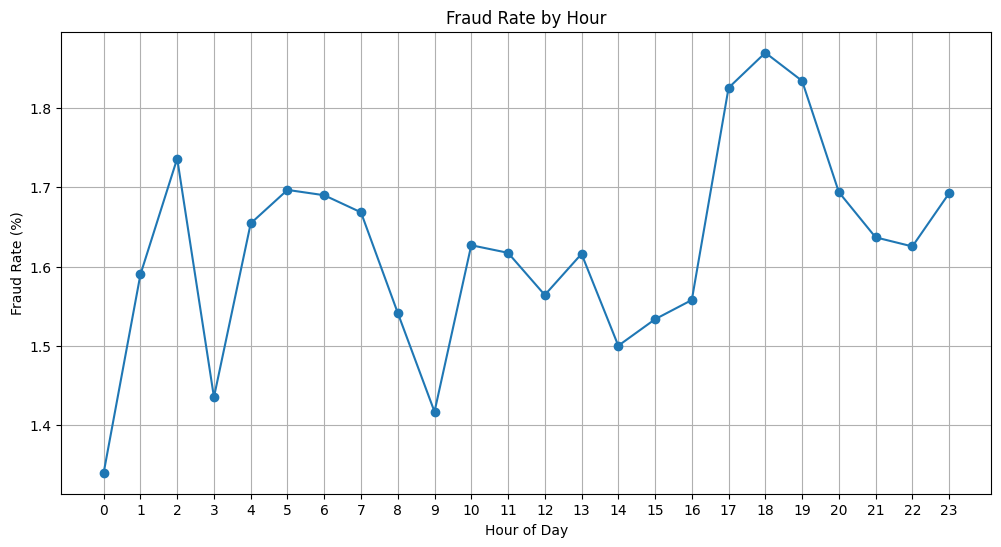

In [47]:
plt.figure(figsize=(12, 6))

plt.plot(
    hourly_fraud.index,
    hourly_fraud["fraud_rate"],
    marker="o"
)

plt.title("Fraud Rate by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(24))
plt.grid(True)

plt.show()


In [48]:
risk_features = [
    "merchant_risk_score",
    "ip_risk_score",
    "post_auth_risk_score"
]

for feature in risk_features:
    print(f"\n{feature}")
    print(
        train_df.groupby("is_fraud")[feature]
        .agg(["count", "mean", "median", "min", "max"])
    )


merchant_risk_score
           count      mean    median       min       max
is_fraud                                                
0         295242  0.251129  0.229110  0.001365  0.837624
1           4871  0.268398  0.246434  0.004244  0.837624

ip_risk_score
           count      mean    median       min       max
is_fraud                                                
0         295242  0.285431  0.264100  0.000345  0.964121
1           4871  0.301891  0.277421  0.002528  0.926549

post_auth_risk_score
           count      mean    median       min       max
is_fraud                                                
0         295242  0.200331  0.200580  0.000001  0.400000
1           4871  0.851771  0.851345  0.700048  0.999861


In [49]:
for feature in risk_features:
    
    missing_by_class = (
        train_df.groupby("is_fraud")[feature]
        .apply(lambda x: x.isna().sum())
    )
    
    print(f"\n{feature}")
    print(missing_by_class)


merchant_risk_score
is_fraud
0    0
1    0
Name: merchant_risk_score, dtype: int64

ip_risk_score
is_fraud
0    0
1    0
Name: ip_risk_score, dtype: int64

post_auth_risk_score
is_fraud
0    0
1    0
Name: post_auth_risk_score, dtype: int64


In [50]:
for feature in risk_features:
    
    missing_rate = (
        train_df.groupby("is_fraud")[feature]
        .apply(lambda x: x.isna().mean() * 100)
    )
    
    print(f"\nMissing Rate: {feature}")
    print(missing_rate)


Missing Rate: merchant_risk_score
is_fraud
0    0.0
1    0.0
Name: merchant_risk_score, dtype: float64

Missing Rate: ip_risk_score
is_fraud
0    0.0
1    0.0
Name: ip_risk_score, dtype: float64

Missing Rate: post_auth_risk_score
is_fraud
0    0.0
1    0.0
Name: post_auth_risk_score, dtype: float64


In [51]:
post_auth_separation = train_df.groupby("is_fraud")[
    "post_auth_risk_score"
].agg(
    min="min",
    max="max",
    mean="mean",
    median="median"
)

post_auth_separation

print(
    "Maximum legitimate score:",
    train_df.loc[
        train_df["is_fraud"] == 0,
        "post_auth_risk_score"
    ].max()
)

print(
    "Minimum fraud score:",
    train_df.loc[
        train_df["is_fraud"] == 1,
        "post_auth_risk_score"
    ].min()
)

Maximum legitimate score: 0.4
Minimum fraud score: 0.700048


In [52]:
legit_max = train_df.loc[
    train_df["is_fraud"] == 0,
    "post_auth_risk_score"
].max()

fraud_min = train_df.loc[
    train_df["is_fraud"] == 1,
    "post_auth_risk_score"
].min()

print("Legitimate maximum:", legit_max)
print("Fraud minimum:", fraud_min)

if legit_max < fraud_min:
    print("⚠️ No overlap between legitimate and fraud scores.")
else:
    print("Some overlap exists.")

Legitimate maximum: 0.4
Fraud minimum: 0.700048
⚠️ No overlap between legitimate and fraud scores.


In [53]:
pd.crosstab(
    pd.cut(
        train_df["post_auth_risk_score"],
        bins=[0, 0.4, 0.7, 1.0],
        include_lowest=True
    ),
    train_df["is_fraud"],
    normalize="index"
) * 100

is_fraud,0,1
post_auth_risk_score,,
"(-0.001, 0.4]",100.0,0.0
"(0.7, 1.0]",0.0,100.0


In [54]:
customer_activity = (
    train_df.groupby("customer_id")
    .size()
    .describe()
)

customer_activity

count    39983.000000
mean         7.506015
std          2.744512
min          1.000000
25%          6.000000
50%          7.000000
75%          9.000000
max         20.000000
dtype: float64

In [55]:
merchant_activity = (
    train_df.groupby("merchant_id")
    .size()
    .describe()
)

merchant_activity

count    8000.000000
mean       37.514125
std         6.128866
min        18.000000
25%        33.000000
50%        37.000000
75%        42.000000
max        67.000000
dtype: float64

In [56]:
customer_fraud = (
    train_df.groupby("customer_id")["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

customer_fraud["fraud_rate"] *= 100

customer_fraud.sort_values(
    "fraud_rate",
    ascending=False
).head(20)

,transaction_count,fraud_count,fraud_rate
customer_id,,,
12187,1,1,100.000000
34235,1,1,100.000000
11257,3,2,66.666667
26315,3,2,66.666667
21465,4,2,50.000000
22850,2,1,50.000000
927,4,2,50.000000
6415,2,1,50.000000
1505,2,1,50.000000


In [57]:
customer_fraud = (
    train_df.groupby("customer_id")["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

customer_fraud["fraud_rate"] *= 100

customer_fraud.sort_values(
    "fraud_rate",
    ascending=False
).head(20)

,transaction_count,fraud_count,fraud_rate
customer_id,,,
12187,1,1,100.000000
34235,1,1,100.000000
11257,3,2,66.666667
26315,3,2,66.666667
21465,4,2,50.000000
22850,2,1,50.000000
927,4,2,50.000000
6415,2,1,50.000000
1505,2,1,50.000000


In [58]:
merchant_fraud = (
    train_df.groupby("merchant_id")["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

merchant_fraud["fraud_rate"] *= 100

merchant_fraud.sort_values(
    "fraud_rate",
    ascending=False
).head(20)

,transaction_count,fraud_count,fraud_rate
merchant_id,,,
5092,27,4,14.814815
4396,34,5,14.705882
7895,36,5,13.888889
1948,29,4,13.793103
3102,40,5,12.500000
7732,33,4,12.121212
1604,34,4,11.764706
3536,27,3,11.111111
6921,36,4,11.111111


In [59]:
print("Training start:")
print(train_df["transaction_time"].min())

print("\nTraining end:")
print(train_df["transaction_time"].max())

Training start:
2023-01-01 00:02:00.328105993

Training end:
2023-09-30 23:56:57.561687899


In [60]:
print("Test start:")
print(test_df["transaction_time"].min())

print("\nTest end:")
print(test_df["transaction_time"].max())

Test start:
2023-10-01 00:02:41.559131982

Test end:
2023-12-30 23:58:52.790967409


In [61]:
train_start = train_df["transaction_time"].min()
train_end = train_df["transaction_time"].max()

test_start = test_df["transaction_time"].min()
test_end = test_df["transaction_time"].max()

print("Train:", train_start, "→", train_end)
print("Test :", test_start, "→", test_end)

if train_end < test_start:
    print("\n✅ Test data occurs after training data.")
else:
    print("\n⚠️ Train and test periods overlap.")

Train: 2023-01-01 00:02:00.328105993 → 2023-09-30 23:56:57.561687899
Test : 2023-10-01 00:02:41.559131982 → 2023-12-30 23:58:52.790967409

✅ Test data occurs after training data.


In [62]:
print("Training transactions by month:")
print(
    train_df["transaction_time"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("\nTest transactions by month:")
print(
    test_df["transaction_time"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

Training transactions by month:
transaction_time
2023-01    33881
2023-02    31006
2023-03    34288
2023-04    32827
2023-05    34042
2023-06    32950
2023-07    34023
2023-08    34207
2023-09    32889
Freq: M, Name: count, dtype: int64

Test transactions by month:
transaction_time
2023-10    34090
2023-11    32839
2023-12    32958
Freq: M, Name: count, dtype: int64


In [63]:
train_customers = set(train_df["customer_id"].unique())
test_customers = set(test_df["customer_id"].unique())

customer_overlap = train_customers.intersection(test_customers)

print("Unique train customers:", len(train_customers))
print("Unique test customers:", len(test_customers))
print("Customers appearing in both:", len(customer_overlap))

Unique train customers: 39983
Unique test customers: 36701
Customers appearing in both: 36685


In [64]:
train_merchants = set(train_df["merchant_id"].unique())
test_merchants = set(test_df["merchant_id"].unique())

merchant_overlap = train_merchants.intersection(test_merchants)

print("Unique train merchants:", len(train_merchants))
print("Unique test merchants:", len(test_merchants))
print("Merchants appearing in both:", len(merchant_overlap))

Unique train merchants: 8000
Unique test merchants: 8000
Merchants appearing in both: 8000


In [65]:
train_df = train_df.sort_values(
    "transaction_time"
).reset_index(drop=True)

test_df = test_df.sort_values(
    "transaction_time"
).reset_index(drop=True)

print("Training sorted:", train_df["transaction_time"].is_monotonic_increasing)
print("Test sorted:", test_df["transaction_time"].is_monotonic_increasing)

Training sorted: True
Test sorted: True


In [66]:
train_df["customer_prev_txn_count"] = (
    train_df.groupby("customer_id")
    .cumcount()
)

train_df[
    [
        "transaction_time",
        "customer_id",
        "is_fraud",
        "customer_prev_txn_count"
    ]
].head(20)

,transaction_time,customer_id,is_fraud,customer_prev_txn_count
0,2023-01-01 00:02:00.328105993,11102,0,0
1,2023-01-01 00:02:26.339769237,22891,0,0
2,2023-01-01 00:06:54.145825305,3102,0,0
3,2023-01-01 00:06:57.723185583,4041,0,0
4,2023-01-01 00:08:05.487541188,3979,0,0
5,2023-01-01 00:09:11.294695623,1941,0,0
6,2023-01-01 00:10:05.075100599,33828,0,0
7,2023-01-01 00:11:53.896526457,17049,0,0
8,2023-01-01 00:13:23.350519980,31559,0,0
9,2023-01-01 00:13:31.431162139,35852,0,0


In [67]:
train_df["merchant_prev_txn_count"] = (
    train_df.groupby("merchant_id")
    .cumcount()
)

train_df[
    [
        "transaction_time",
        "merchant_id",
        "is_fraud",
        "merchant_prev_txn_count"
    ]
].head(20)

,transaction_time,merchant_id,is_fraud,merchant_prev_txn_count
0,2023-01-01 00:02:00.328105993,2282,0,0
1,2023-01-01 00:02:26.339769237,3016,0,0
2,2023-01-01 00:06:54.145825305,1855,0,0
3,2023-01-01 00:06:57.723185583,2525,0,0
4,2023-01-01 00:08:05.487541188,1555,0,0
5,2023-01-01 00:09:11.294695623,6085,0,0
6,2023-01-01 00:10:05.075100599,1973,0,0
7,2023-01-01 00:11:53.896526457,5736,0,0
8,2023-01-01 00:13:23.350519980,2485,0,0
9,2023-01-01 00:13:31.431162139,1281,0,0


In [68]:
customer_cumulative_fraud = (
    train_df.groupby("customer_id")["is_fraud"]
    .cumsum()
)

train_df["customer_prev_fraud_count"] = (
    customer_cumulative_fraud
    .groupby(train_df["customer_id"])
    .shift(1)
    .fillna(0)
)

In [69]:
merchant_cumulative_fraud = (
    train_df.groupby("merchant_id")["is_fraud"]
    .cumsum()
)

train_df["merchant_prev_fraud_count"] = (
    merchant_cumulative_fraud
    .groupby(train_df["merchant_id"])
    .shift(1)
    .fillna(0)
)

In [70]:
check_cols = [
    "transaction_time",
    "customer_id",
    "is_fraud",
    "customer_prev_txn_count",
    "customer_prev_fraud_count",
    "merchant_id",
    "merchant_prev_txn_count",
    "merchant_prev_fraud_count"
]

train_df[check_cols].head(30)

,transaction_time,customer_id,is_fraud,customer_prev_txn_count,customer_prev_fraud_count,merchant_id,merchant_prev_txn_count,merchant_prev_fraud_count
0,2023-01-01 00:02:00.328105993,11102,0,0,0.0,2282,0,0.0
1,2023-01-01 00:02:26.339769237,22891,0,0,0.0,3016,0,0.0
2,2023-01-01 00:06:54.145825305,3102,0,0,0.0,1855,0,0.0
3,2023-01-01 00:06:57.723185583,4041,0,0,0.0,2525,0,0.0
4,2023-01-01 00:08:05.487541188,3979,0,0,0.0,1555,0,0.0
5,2023-01-01 00:09:11.294695623,1941,0,0,0.0,6085,0,0.0
6,2023-01-01 00:10:05.075100599,33828,0,0,0.0,1973,0,0.0
7,2023-01-01 00:11:53.896526457,17049,0,0,0.0,5736,0,0.0
8,2023-01-01 00:13:23.350519980,31559,0,0,0.0,2485,0,0.0
9,2023-01-01 00:13:31.431162139,35852,0,0,0.0,1281,0,0.0


In [71]:
train_df["customer_prev_fraud_rate"] = np.where(
    train_df["customer_prev_txn_count"] > 0,
    train_df["customer_prev_fraud_count"] /
    train_df["customer_prev_txn_count"],
    0
)

train_df[
    [
        "customer_id",
        "customer_prev_txn_count",
        "customer_prev_fraud_count",
        "customer_prev_fraud_rate",
        "is_fraud"
    ]
].head(30)

,customer_id,customer_prev_txn_count,customer_prev_fraud_count,customer_prev_fraud_rate,is_fraud
0,11102,0,0.0,0.0,0
1,22891,0,0.0,0.0,0
2,3102,0,0.0,0.0,0
3,4041,0,0.0,0.0,0
4,3979,0,0.0,0.0,0
5,1941,0,0.0,0.0,0
6,33828,0,0.0,0.0,0
7,17049,0,0.0,0.0,0
8,31559,0,0.0,0.0,0
9,35852,0,0.0,0.0,0


In [72]:
train_df["merchant_prev_fraud_rate"] = np.where(
    train_df["merchant_prev_txn_count"] > 0,
    train_df["merchant_prev_fraud_count"] /
    train_df["merchant_prev_txn_count"],
    0
)

train_df[
    [
        "merchant_id",
        "merchant_prev_txn_count",
        "merchant_prev_fraud_count",
        "merchant_prev_fraud_rate",
        "is_fraud"
    ]
].head(30)

,merchant_id,merchant_prev_txn_count,merchant_prev_fraud_count,merchant_prev_fraud_rate,is_fraud
0,2282,0,0.0,0.0,0
1,3016,0,0.0,0.0,0
2,1855,0,0.0,0.0,0
3,2525,0,0.0,0.0,0
4,1555,0,0.0,0.0,0
5,6085,0,0.0,0.0,0
6,1973,0,0.0,0.0,0
7,5736,0,0.0,0.0,0
8,2485,0,0.0,0.0,0
9,1281,0,0.0,0.0,0


In [73]:
historical_features = [
    "customer_prev_txn_count",
    "customer_prev_fraud_count",
    "customer_prev_fraud_rate",
    "merchant_prev_txn_count",
    "merchant_prev_fraud_count",
    "merchant_prev_fraud_rate"
]

train_df[historical_features].describe()

,customer_prev_txn_count,customer_prev_fraud_count,customer_prev_fraud_rate,merchant_prev_txn_count,merchant_prev_fraud_count,merchant_prev_fraud_rate
count,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000
mean,3.754749,0.056922,0.012977,18.757651,0.286352,0.014513
std,2.907457,0.241937,0.069146,11.667258,0.563240,0.039478
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,9.000000,0.000000,0.000000
50%,3.000000,0.000000,0.000000,18.000000,0.000000,0.000000
75%,6.000000,0.000000,0.000000,28.000000,0.000000,0.000000
max,19.000000,3.000000,1.000000,66.000000,5.000000,1.000000


In [74]:
print(
    train_df[
        [
            "is_fraud",
            "customer_prev_fraud_count",
            "customer_prev_fraud_rate",
            "merchant_prev_fraud_count",
            "merchant_prev_fraud_rate"
        ]
    ].corr()
)

                           is_fraud  customer_prev_fraud_count  \
is_fraud                   1.000000                   0.002478   
customer_prev_fraud_count  0.002478                   1.000000   
customer_prev_fraud_rate   0.004037                   0.778488   
merchant_prev_fraud_count  0.006235                   0.047150   
merchant_prev_fraud_rate   0.002786                   0.004982   

                           customer_prev_fraud_rate  \
is_fraud                                   0.004037   
customer_prev_fraud_count                  0.778488   
customer_prev_fraud_rate                   1.000000   
merchant_prev_fraud_count                  0.015838   
merchant_prev_fraud_rate                   0.002440   

                           merchant_prev_fraud_count  merchant_prev_fraud_rate  
is_fraud                                    0.006235                  0.002786  
customer_prev_fraud_count                   0.047150                  0.004982  
customer_prev_fraud_rate     

In [75]:
customer_amount_sum = (
    train_df.groupby("customer_id")["transaction_amount"]
    .cumsum()
)

train_df["customer_prev_avg_amount"] = (
    customer_amount_sum
    .groupby(train_df["customer_id"])
    .shift(1)
    /
    train_df["customer_prev_txn_count"].replace(0, np.nan)
)

train_df["customer_prev_avg_amount"] = (
    train_df["customer_prev_avg_amount"].fillna(0)
)

In [76]:
merchant_amount_sum = (
    train_df.groupby("merchant_id")["transaction_amount"]
    .cumsum()
)

train_df["merchant_prev_avg_amount"] = (
    merchant_amount_sum
    .groupby(train_df["merchant_id"])
    .shift(1)
    /
    train_df["merchant_prev_txn_count"].replace(0, np.nan)
)

train_df["merchant_prev_avg_amount"] = (
    train_df["merchant_prev_avg_amount"].fillna(0)
)

In [77]:
train_df["customer_amount_ratio"] = np.where(
    train_df["customer_prev_avg_amount"] > 0,
    train_df["transaction_amount"] /
    train_df["customer_prev_avg_amount"],
    1.0
)

In [78]:
train_df["merchant_amount_ratio"] = np.where(
    train_df["merchant_prev_avg_amount"] > 0,
    train_df["transaction_amount"] /
    train_df["merchant_prev_avg_amount"],
    1.0
)

In [79]:
new_historical_features = [
    "customer_prev_txn_count",
    "customer_prev_fraud_count",
    "customer_prev_fraud_rate",
    "customer_prev_avg_amount",
    "customer_amount_ratio",
    "merchant_prev_txn_count",
    "merchant_prev_fraud_count",
    "merchant_prev_fraud_rate",
    "merchant_prev_avg_amount",
    "merchant_amount_ratio"
]

train_df[new_historical_features].describe()

,customer_prev_txn_count,customer_prev_fraud_count,customer_prev_fraud_rate,customer_prev_avg_amount,customer_amount_ratio,merchant_prev_txn_count,merchant_prev_fraud_count,merchant_prev_fraud_rate,merchant_prev_avg_amount,merchant_amount_ratio
count,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000,300113.000000
mean,3.754749,0.056922,0.012977,2085.208643,1.248603,18.757651,0.286352,0.014513,2340.135633,1.073654
std,2.907457,0.241937,0.069146,1269.919361,2.006321,11.667258,0.563240,0.039478,687.596589,1.430019
min,0.000000,0.000000,0.000000,0.000000,0.001583,0.000000,0.000000,0.000000,0.000000,0.001962
25%,1.000000,0.000000,0.000000,1402.926090,0.537890,9.000000,0.000000,0.000000,2071.637766,0.489886
50%,3.000000,0.000000,0.000000,2129.832284,1.000000,18.000000,0.000000,0.000000,2362.830616,0.877822
75%,6.000000,0.000000,0.000000,2788.859268,1.413208,28.000000,0.000000,0.000000,2656.558157,1.381969
max,19.000000,3.000000,1.000000,16500.126347,254.610253,66.000000,5.000000,1.000000,12694.991284,522.230820


In [80]:
train_df[
    [
        "transaction_time",
        "customer_id",
        "transaction_amount",
        "customer_prev_txn_count",
        "customer_prev_fraud_rate",
        "customer_prev_avg_amount",
        "customer_amount_ratio",
        "merchant_id",
        "merchant_prev_txn_count",
        "merchant_prev_fraud_rate",
        "merchant_prev_avg_amount",
        "merchant_amount_ratio",
        "is_fraud"
    ]
].head(30)

,transaction_time,customer_id,transaction_amount,customer_prev_txn_count,customer_prev_fraud_rate,customer_prev_avg_amount,customer_amount_ratio,merchant_id,merchant_prev_txn_count,merchant_prev_fraud_rate,merchant_prev_avg_amount,merchant_amount_ratio,is_fraud
0,2023-01-01 00:02:00.328105993,11102,2408.320473,0,0.0,0.0,1.0,2282,0,0.0,0.000000,1.000000,0
1,2023-01-01 00:02:26.339769237,22891,2765.255095,0,0.0,0.0,1.0,3016,0,0.0,0.000000,1.000000,0
2,2023-01-01 00:06:54.145825305,3102,1529.079168,0,0.0,0.0,1.0,1855,0,0.0,0.000000,1.000000,0
3,2023-01-01 00:06:57.723185583,4041,610.407487,0,0.0,0.0,1.0,2525,0,0.0,0.000000,1.000000,0
4,2023-01-01 00:08:05.487541188,3979,986.397163,0,0.0,0.0,1.0,1555,0,0.0,0.000000,1.000000,0
5,2023-01-01 00:09:11.294695623,1941,1780.932827,0,0.0,0.0,1.0,6085,0,0.0,0.000000,1.000000,0
6,2023-01-01 00:10:05.075100599,33828,4478.461175,0,0.0,0.0,1.0,1973,0,0.0,0.000000,1.000000,0
7,2023-01-01 00:11:53.896526457,17049,764.891641,0,0.0,0.0,1.0,5736,0,0.0,0.000000,1.000000,0
8,2023-01-01 00:13:23.350519980,31559,516.009939,0,0.0,0.0,1.0,2485,0,0.0,0.000000,1.000000,0
9,2023-01-01 00:13:31.431162139,35852,430.208442,0,0.0,0.0,1.0,1281,0,0.0,0.000000,1.000000,0


In [81]:
global_fraud_rate = train_df["is_fraud"].mean()

print("Global fraud rate:", global_fraud_rate)
print("Global fraud rate (%):", global_fraud_rate * 100)

Global fraud rate: 0.01623055315831037
Global fraud rate (%): 1.623055315831037


In [82]:
alpha = 10

train_df["customer_smoothed_fraud_rate"] = (
    train_df["customer_prev_fraud_count"] +
    alpha * global_fraud_rate
) / (
    train_df["customer_prev_txn_count"] +
    alpha
)

In [83]:
train_df["merchant_smoothed_fraud_rate"] = (
    train_df["merchant_prev_fraud_count"] +
    alpha * global_fraud_rate
) / (
    train_df["merchant_prev_txn_count"] +
    alpha
)

In [84]:
train_df[
    [
        "customer_prev_txn_count",
        "customer_prev_fraud_count",
        "customer_prev_fraud_rate",
        "customer_smoothed_fraud_rate",
        "merchant_prev_txn_count",
        "merchant_prev_fraud_count",
        "merchant_prev_fraud_rate",
        "merchant_smoothed_fraud_rate"
    ]
].head(30)

,customer_prev_txn_count,customer_prev_fraud_count,customer_prev_fraud_rate,customer_smoothed_fraud_rate,merchant_prev_txn_count,merchant_prev_fraud_count,merchant_prev_fraud_rate,merchant_smoothed_fraud_rate
0,0,0.0,0.0,0.016231,0,0.0,0.0,0.016231
1,0,0.0,0.0,0.016231,0,0.0,0.0,0.016231
2,0,0.0,0.0,0.016231,0,0.0,0.0,0.016231
3,0,0.0,0.0,0.016231,0,0.0,0.0,0.016231
4,0,0.0,0.0,0.016231,0,0.0,0.0,0.016231
5,0,0.0,0.0,0.016231,0,0.0,0.0,0.016231
6,0,0.0,0.0,0.016231,0,0.0,0.0,0.016231
7,0,0.0,0.0,0.016231,0,0.0,0.0,0.016231
8,0,0.0,0.0,0.016231,0,0.0,0.0,0.016231
9,0,0.0,0.0,0.016231,0,0.0,0.0,0.016231


In [85]:
print("Customer raw max:",
      train_df["customer_prev_fraud_rate"].max())

print("Customer smoothed max:",
      train_df["customer_smoothed_fraud_rate"].max())

print()

print("Merchant raw max:",
      train_df["merchant_prev_fraud_rate"].max())

print("Merchant smoothed max:",
      train_df["merchant_smoothed_fraud_rate"].max())

Customer raw max: 1.0
Customer smoothed max: 0.24325427166023875

Merchant raw max: 1.0
Merchant smoothed max: 0.19764409572394398


In [86]:
# ============================================================
# TEMPORAL SPLIT MOVED TO CELL 89
# ============================================================

print(
    "Temporal train/validation split is handled in Cell 89."
)

Temporal train/validation split is handled in Cell 89.


In [87]:
# ============================================================
# LEAKAGE-SAFE HISTORICAL FEATURE ENGINEERING
# ============================================================

def create_historical_features(
    df,
    customer_history=None,
    merchant_history=None,
    update_history=True
):
    """
    Creates historical customer/merchant features using
    ONLY information available BEFORE the current transaction.

    update_history=True:
        Used for labeled training data.

    update_history=False:
        Used for validation/test data.
        Current fraud labels are NOT used to update history.
    """

    df = df.copy()

    # --------------------------------------------------------
    # Convert transaction time
    # --------------------------------------------------------

    df["transaction_time"] = pd.to_datetime(
        df["transaction_time"]
    )

    # --------------------------------------------------------
    # Sort chronologically
    # --------------------------------------------------------

    df = (
        df
        .sort_values("transaction_time")
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Initialize history
    # --------------------------------------------------------

    if customer_history is None:
        customer_history = {}

    if merchant_history is None:
        merchant_history = {}

    # --------------------------------------------------------
    # Historical feature lists
    # --------------------------------------------------------

    customer_prev_txn = []
    customer_prev_fraud = []
    customer_prev_amount_sum = []

    merchant_prev_txn = []
    merchant_prev_fraud = []
    merchant_prev_amount_sum = []

    # ========================================================
    # PROCESS TRANSACTIONS SEQUENTIALLY
    # ========================================================

    for _, row in df.iterrows():

        customer_id = row["customer_id"]
        merchant_id = row["merchant_id"]

        # ====================================================
        # CUSTOMER HISTORY BEFORE CURRENT TRANSACTION
        # ====================================================

        c_hist = customer_history.get(
            customer_id,
            {
                "txn": 0,
                "fraud": 0,
                "amount_sum": 0.0
            }
        )

        customer_prev_txn.append(
            c_hist["txn"]
        )

        customer_prev_fraud.append(
            c_hist["fraud"]
        )

        customer_prev_amount_sum.append(
            c_hist["amount_sum"]
        )

        # ====================================================
        # MERCHANT HISTORY BEFORE CURRENT TRANSACTION
        # ====================================================

        m_hist = merchant_history.get(
            merchant_id,
            {
                "txn": 0,
                "fraud": 0,
                "amount_sum": 0.0
            }
        )

        merchant_prev_txn.append(
            m_hist["txn"]
        )

        merchant_prev_fraud.append(
            m_hist["fraud"]
        )

        merchant_prev_amount_sum.append(
            m_hist["amount_sum"]
        )

        # ====================================================
        # UPDATE HISTORY ONLY WHEN ALLOWED
        # ====================================================

        if update_history:

            if "is_fraud" not in df.columns:
                raise ValueError(
                    "is_fraud column is required when "
                    "update_history=True"
                )

            transaction_amount = float(
                row["transaction_amount"]
            )

            fraud_label = int(
                row["is_fraud"]
            )

            # ------------------------------------------------
            # Update customer history
            # ------------------------------------------------

            customer_history[customer_id] = {
                "txn": c_hist["txn"] + 1,

                "fraud": (
                    c_hist["fraud"]
                    + fraud_label
                ),

                "amount_sum": (
                    c_hist["amount_sum"]
                    + transaction_amount
                )
            }

            # ------------------------------------------------
            # Update merchant history
            # ------------------------------------------------

            merchant_history[merchant_id] = {
                "txn": m_hist["txn"] + 1,

                "fraud": (
                    m_hist["fraud"]
                    + fraud_label
                ),

                "amount_sum": (
                    m_hist["amount_sum"]
                    + transaction_amount
                )
            }

    # ========================================================
    # CUSTOMER HISTORICAL FEATURES
    # ========================================================

    df["customer_prev_txn_count"] = (
        customer_prev_txn
    )

    df["customer_prev_fraud_count"] = (
        customer_prev_fraud
    )

    # Previous average transaction amount
    df["customer_prev_avg_amount"] = [
        amount_sum / txn_count
        if txn_count > 0
        else np.nan
        for amount_sum, txn_count
        in zip(
            customer_prev_amount_sum,
            customer_prev_txn
        )
    ]

    # Previous customer fraud rate
    df["customer_prev_fraud_rate"] = [
        fraud_count / txn_count
        if txn_count > 0
        else 0.0
        for fraud_count, txn_count
        in zip(
            customer_prev_fraud,
            customer_prev_txn
        )
    ]

    # ========================================================
    # MERCHANT HISTORICAL FEATURES
    # ========================================================

    df["merchant_prev_txn_count"] = (
        merchant_prev_txn
    )

    df["merchant_prev_fraud_count"] = (
        merchant_prev_fraud
    )

    # Previous average transaction amount
    df["merchant_prev_avg_amount"] = [
        amount_sum / txn_count
        if txn_count > 0
        else np.nan
        for amount_sum, txn_count
        in zip(
            merchant_prev_amount_sum,
            merchant_prev_txn
        )
    ]

    # Previous merchant fraud rate
    df["merchant_prev_fraud_rate"] = [
        fraud_count / txn_count
        if txn_count > 0
        else 0.0
        for fraud_count, txn_count
        in zip(
            merchant_prev_fraud,
            merchant_prev_txn
        )
    ]

    # ========================================================
    # RETURN
    # ========================================================

    return (
        df,
        customer_history,
        merchant_history
    )

In [88]:
train_df = train_df.copy()

train_df["transaction_time"] = pd.to_datetime(
    train_df["transaction_time"]
)

train_df = (
    train_df
    .sort_values("transaction_time")
    .reset_index(drop=True)
)

print("Training data sorted chronologically.")
print("Shape:", train_df.shape)

print(
    "Start:",
    train_df["transaction_time"].min()
)

print(
    "End:",
    train_df["transaction_time"].max()
)

Training data sorted chronologically.
Shape: (300113, 38)
Start: 2023-01-01 00:02:00.328105993
End: 2023-09-30 23:56:57.561687899


In [89]:
print(
    "Maximum customer previous fraud count:",
    train_df["customer_prev_fraud_count"].max()
)

print(
    "Maximum merchant previous fraud count:",
    train_df["merchant_prev_fraud_count"].max()
)

print(
    "First transaction customer previous count:",
    train_df.iloc[0]["customer_prev_txn_count"]
)

print(
    "First transaction merchant previous count:",
    train_df.iloc[0]["merchant_prev_txn_count"]
)

Maximum customer previous fraud count: 3.0
Maximum merchant previous fraud count: 5.0
First transaction customer previous count: 0
First transaction merchant previous count: 0


In [90]:
# ============================================================
# TEMPORAL TRAIN / VALIDATION SPLIT
# ============================================================

validation_start = pd.Timestamp(
    "2023-09-01"
)

# ============================================================
# PREPARE RAW TRAINING DATA
# ============================================================

raw_train_df = train_df.copy()

raw_train_df["transaction_time"] = pd.to_datetime(
    raw_train_df["transaction_time"]
)

raw_train_df = (
    raw_train_df
    .sort_values("transaction_time")
    .reset_index(drop=True)
)

# ============================================================
# SPLIT RAW DATA FIRST
# ============================================================

model_train_raw = (
    raw_train_df[
        raw_train_df["transaction_time"] < validation_start
    ]
    .copy()
)

validation_raw = (
    raw_train_df[
        raw_train_df["transaction_time"] >= validation_start
    ]
    .copy()
)

# ============================================================
# DISPLAY TEMPORAL SPLIT
# ============================================================

print("=" * 70)
print("TEMPORAL DATA SPLIT")
print("=" * 70)

print(
    "\nModel Training:",
    model_train_raw.shape
)

print(
    "Period:",
    model_train_raw["transaction_time"].min(),
    "→",
    model_train_raw["transaction_time"].max()
)

print(
    "\nValidation:",
    validation_raw.shape
)

print(
    "Period:",
    validation_raw["transaction_time"].min(),
    "→",
    validation_raw["transaction_time"].max()
)

# ============================================================
# CREATE TRAIN HISTORICAL FEATURES
# ============================================================
#
# Training data is labeled, so history can be updated
# sequentially using previous confirmed fraud labels.
# ============================================================

model_train_df, customer_history, merchant_history = (
    create_historical_features(
        model_train_raw,
        update_history=True
    )
)

# ============================================================
# CREATE VALIDATION HISTORICAL FEATURES
# ============================================================
#
# Validation starts with history accumulated from the
# training period.
#
# IMPORTANT:
# Validation fraud labels are NOT used to update history.
# ============================================================

validation_df, _, _ = (
    create_historical_features(
        validation_raw,
        customer_history=customer_history.copy(),
        merchant_history=merchant_history.copy(),
        update_history=False
    )
)

# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("HISTORICAL FEATURES GENERATED")
print("=" * 70)

print(
    "Model Train:",
    model_train_df.shape
)

print(
    "Validation :",
    validation_df.shape
)

print("\nHistorical feature columns:")

historical_columns = [
    "customer_prev_txn_count",
    "customer_prev_fraud_count",
    "customer_prev_avg_amount",
    "customer_prev_fraud_rate",
    "merchant_prev_txn_count",
    "merchant_prev_fraud_count",
    "merchant_prev_avg_amount",
    "merchant_prev_fraud_rate"
]

print(historical_columns)

TEMPORAL DATA SPLIT

Model Training: (267224, 38)
Period: 2023-01-01 00:02:00.328105993 → 2023-08-31 23:59:29.214879960

Validation: (32889, 38)
Period: 2023-09-01 00:00:00.687812227 → 2023-09-30 23:56:57.561687899

HISTORICAL FEATURES GENERATED
Model Train: (267224, 38)
Validation : (32889, 38)

Historical feature columns:
['customer_prev_txn_count', 'customer_prev_fraud_count', 'customer_prev_avg_amount', 'customer_prev_fraud_rate', 'merchant_prev_txn_count', 'merchant_prev_fraud_count', 'merchant_prev_avg_amount', 'merchant_prev_fraud_rate']


In [91]:
# ============================================================
# HISTORICAL FEATURE VERIFICATION
# ============================================================

historical_features = [
    "customer_prev_txn_count",
    "customer_prev_fraud_count",
    "customer_prev_fraud_rate",
    "merchant_prev_txn_count",
    "merchant_prev_fraud_count",
    "merchant_prev_fraud_rate"
]

print("=" * 60)
print("MODEL TRAINING HISTORICAL FEATURES")
print("=" * 60)

display(
    model_train_df[historical_features].describe().round(4)
)

print("\n" + "=" * 60)
print("VALIDATION HISTORICAL FEATURES")
print("=" * 60)

display(
    validation_df[historical_features].describe().round(4)
)

print("\n" + "=" * 60)
print("VALIDATION FIRST 10 TRANSACTIONS")
print("=" * 60)

display(
    validation_df[
        [
            "transaction_time",
            "customer_id",
            "merchant_id",
            "is_fraud",
            "customer_prev_txn_count",
            "customer_prev_fraud_count",
            "merchant_prev_txn_count",
            "merchant_prev_fraud_count"
        ]
    ].head(10)
)

MODEL TRAINING HISTORICAL FEATURES


,customer_prev_txn_count,customer_prev_fraud_count,customer_prev_fraud_rate,merchant_prev_txn_count,merchant_prev_fraud_count,merchant_prev_fraud_rate
count,267224.0000,267224.0000,267224.0000,267224.0000,267224.0000,267224.0000
mean,3.3427,0.0499,0.0126,16.7023,0.2507,0.0143
std,2.6582,0.2265,0.0711,10.4753,0.5231,0.0411
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,1.0000,0.0000,0.0000,8.0000,0.0000,0.0000
50%,3.0000,0.0000,0.0000,16.0000,0.0000,0.0000
75%,5.0000,0.0000,0.0000,25.0000,0.0000,0.0000
max,18.0000,3.0000,1.0000,62.0000,5.0000,1.0000



VALIDATION HISTORICAL FEATURES


,customer_prev_txn_count,customer_prev_fraud_count,customer_prev_fraud_rate,merchant_prev_txn_count,merchant_prev_fraud_count,merchant_prev_fraud_rate
count,32889.0000,32889.0000,32889.0000,32889.0000,32889.0000,32889.0000
mean,6.6897,0.1058,0.0157,33.4082,0.5360,0.0161
std,2.5812,0.3251,0.0525,5.8113,0.7282,0.0220
min,0.0000,0.0000,0.0000,14.0000,0.0000,0.0000
25%,5.0000,0.0000,0.0000,29.0000,0.0000,0.0000
50%,7.0000,0.0000,0.0000,33.0000,0.0000,0.0000
75%,8.0000,0.0000,0.0000,37.0000,1.0000,0.0303
max,19.0000,3.0000,1.0000,63.0000,5.0000,0.1600



VALIDATION FIRST 10 TRANSACTIONS


,transaction_time,customer_id,merchant_id,is_fraud,customer_prev_txn_count,customer_prev_fraud_count,merchant_prev_txn_count,merchant_prev_fraud_count
0,2023-09-01 00:00:00.687812227,19507,5307,0,5,1,27,0
1,2023-09-01 00:00:24.229306266,38368,2155,0,8,1,26,0
2,2023-09-01 00:00:25.315021444,25163,362,0,7,0,33,1
3,2023-09-01 00:04:35.945550123,1536,6335,0,2,0,18,1
4,2023-09-01 00:04:36.855041958,18542,1907,0,7,0,32,2
5,2023-09-01 00:04:37.936956636,27340,6186,0,7,0,37,0
6,2023-09-01 00:05:14.477336533,31376,1530,0,3,0,38,0
7,2023-09-01 00:08:03.645181517,8288,6934,0,3,0,30,0
8,2023-09-01 00:10:33.076210167,32952,591,0,4,0,31,0
9,2023-09-01 00:10:43.185515252,39710,3489,0,10,1,26,1


In [92]:
# ============================================================
# LEAKAGE & DATA INTEGRITY CHECK
# ============================================================

print("=" * 60)
print("DATA INTEGRITY CHECK")
print("=" * 60)

# Current fraud label historical fraud count mein directly
# include nahi hona chahiye.
print(
    "Maximum customer previous fraud count:",
    model_train_df["customer_prev_fraud_count"].max()
)

print(
    "Maximum merchant previous fraud count:",
    model_train_df["merchant_prev_fraud_count"].max()
)

# First transaction of the complete chronological dataset
# should have no previous customer/merchant history.
first_row = model_train_df.iloc[0]

print("\nFirst model-training transaction:")
print(
    "Customer previous transactions:",
    first_row["customer_prev_txn_count"]
)

print(
    "Customer previous frauds:",
    first_row["customer_prev_fraud_count"]
)

print(
    "Merchant previous transactions:",
    first_row["merchant_prev_txn_count"]
)

print(
    "Merchant previous frauds:",
    first_row["merchant_prev_fraud_count"]
)

# Check whether any historical fraud count exceeds
# corresponding historical transaction count.
customer_invalid = (
    model_train_df["customer_prev_fraud_count"]
    >
    model_train_df["customer_prev_txn_count"]
).sum()

merchant_invalid = (
    model_train_df["merchant_prev_fraud_count"]
    >
    model_train_df["merchant_prev_txn_count"]
).sum()

print("\nInvalid customer historical records:", customer_invalid)
print("Invalid merchant historical records:", merchant_invalid)

# Check target distribution
print("\n" + "=" * 60)
print("TARGET DISTRIBUTION")
print("=" * 60)

print("\nModel Training:")
print(model_train_df["is_fraud"].value_counts())
print(
    "Fraud rate:",
    round(model_train_df["is_fraud"].mean() * 100, 4),
    "%"
)

print("\nValidation:")
print(validation_df["is_fraud"].value_counts())
print(
    "Fraud rate:",
    round(validation_df["is_fraud"].mean() * 100, 4),
    "%"
)

DATA INTEGRITY CHECK
Maximum customer previous fraud count: 3
Maximum merchant previous fraud count: 5

First model-training transaction:
Customer previous transactions: 0
Customer previous frauds: 0
Merchant previous transactions: 0
Merchant previous frauds: 0

Invalid customer historical records: 0
Invalid merchant historical records: 0

TARGET DISTRIBUTION

Model Training:
is_fraud
0    262978
1      4246
Name: count, dtype: int64
Fraud rate: 1.5889 %

Validation:
is_fraud
0    32264
1      625
Name: count, dtype: int64
Fraud rate: 1.9003 %


In [93]:
# ============================================================
# ADVANCED FEATURE ENGINEERING
# ============================================================

def add_engineered_features(df):
    df = df.copy()

    # --------------------------------------------------------
    # 1. TEMPORAL FEATURES
    # --------------------------------------------------------

    df["hour"] = df["transaction_time"].dt.hour
    df["day_of_week"] = df["transaction_time"].dt.dayofweek
    df["day_of_month"] = df["transaction_time"].dt.day
    df["month"] = df["transaction_time"].dt.month

    df["is_weekend"] = (
        df["day_of_week"] >= 5
    ).astype(int)

    # Late-night transactions
    df["is_late_night"] = (
        (df["hour"] >= 0) &
        (df["hour"] < 6)
    ).astype(int)

    # Evening transactions
    df["is_evening"] = (
        (df["hour"] >= 18) &
        (df["hour"] < 24)
    ).astype(int)


    # --------------------------------------------------------
    # 2. TRANSACTION AMOUNT FEATURES
    # --------------------------------------------------------

    # Transaction amount relative to user's average spend
    df["amount_to_monthly_spend"] = (
        df["transaction_amount"] /
        (df["avg_monthly_spend"] + 1)
    )

    # Absolute deviation from user's normal behavior
    df["abs_amount_deviation"] = (
        df["amount_deviation_from_user_mean"].abs()
    )

    # Relative amount deviation
    df["relative_amount_deviation"] = (
        df["abs_amount_deviation"] /
        (df["avg_monthly_spend"] + 1)
    )

    # High-value transaction indicator
    df["high_value_transaction"] = (
        df["amount_to_monthly_spend"] > 0.5
    ).astype(int)


    # --------------------------------------------------------
    # 3. TRANSACTION VELOCITY FEATURES
    # --------------------------------------------------------

    # Difference between 24h and 1h activity
    df["txn_velocity_ratio"] = (
        df["txn_count_1h"] /
        (df["txn_count_24h"] + 1)
    )

    # Failed transaction ratio
    df["failed_txn_ratio"] = (
        df["failed_txn_count_24h"] /
        (df["txn_count_24h"] + 1)
    )

    # High velocity indicators
    df["high_velocity_1h"] = (
        df["txn_count_1h"] >= 4
    ).astype(int)

    df["high_velocity_24h"] = (
        df["txn_count_24h"] >= 6
    ).astype(int)

    df["multiple_failures"] = (
        df["failed_txn_count_24h"] >= 2
    ).astype(int)


    # --------------------------------------------------------
    # 4. CUSTOMER BEHAVIOR FEATURES
    # --------------------------------------------------------

    df["customer_activity_level"] = (
        df["customer_prev_txn_count"]
    )

    df["customer_has_fraud_history"] = (
        df["customer_prev_fraud_count"] > 0
    ).astype(int)

    df["customer_risk_signal"] = (
        df["customer_prev_fraud_rate"] *
        np.log1p(df["customer_prev_txn_count"])
    )


    # --------------------------------------------------------
    # 5. MERCHANT BEHAVIOR FEATURES
    # --------------------------------------------------------

    df["merchant_has_fraud_history"] = (
        df["merchant_prev_fraud_count"] > 0
    ).astype(int)

    df["merchant_risk_signal"] = (
        df["merchant_prev_fraud_rate"] *
        np.log1p(df["merchant_prev_txn_count"])
    )


    # --------------------------------------------------------
    # 6. GEOLOCATION FEATURES
    # --------------------------------------------------------

    df["large_geo_distance"] = (
        df["geo_distance_from_last_txn"] >= 100
    ).astype(int)

    # Geo distance normalized by account age
    df["geo_distance_per_account_day"] = (
        df["geo_distance_from_last_txn"] /
        (df["account_age_days"] + 1)
    )


    # --------------------------------------------------------
    # 7. RISK SCORE FEATURES
    # --------------------------------------------------------

    # Combined external risk
    df["combined_external_risk"] = (
        df["merchant_risk_score"] +
        df["ip_risk_score"]
    ) / 2

    # Maximum external risk
    df["max_external_risk"] = df[
        ["merchant_risk_score", "ip_risk_score"]
    ].max(axis=1)

    # Risk difference
    df["risk_score_difference"] = (
        df["ip_risk_score"] -
        df["merchant_risk_score"]
    ).abs()


    # --------------------------------------------------------
    # 8. RISK INTERACTION FEATURES
    # --------------------------------------------------------

    df["international_ip_risk"] = (
        df["is_international"] *
        df["ip_risk_score"]
    )

    df["international_merchant_risk"] = (
        df["is_international"] *
        df["merchant_risk_score"]
    )

    df["international_high_risk"] = (
        (
            df["is_international"] == 1
        ) &
        (
            df["ip_risk_score"] > 0.5
        )
    ).astype(int)

    df["velocity_failed_risk"] = (
        df["txn_count_24h"] *
        (df["failed_txn_count_24h"] + 1)
    )


    # --------------------------------------------------------
    # 9. HISTORICAL RISK INTERACTIONS
    # --------------------------------------------------------

    df["customer_merchant_fraud_signal"] = (
        df["customer_prev_fraud_rate"] +
        df["merchant_prev_fraud_rate"]
    )

    df["historical_fraud_count"] = (
        df["customer_prev_fraud_count"] +
        df["merchant_prev_fraud_count"]
    )

    df["historical_activity"] = (
        df["customer_prev_txn_count"] +
        df["merchant_prev_txn_count"]
    )


    # --------------------------------------------------------
    # 10. COMPOSITE RISK SIGNAL
    # --------------------------------------------------------

    df["behavioral_risk_signal"] = (
        df["failed_txn_ratio"] +
        df["customer_prev_fraud_rate"] +
        df["merchant_prev_fraud_rate"]
    )

    df["transaction_risk_signal"] = (
        df["combined_external_risk"] +
        df["behavioral_risk_signal"] +
        df["international_ip_risk"]
    )

    return df


# ============================================================
# APPLY FEATURE ENGINEERING
# ============================================================

model_train_df = add_engineered_features(model_train_df)

validation_df = add_engineered_features(validation_df)


# ============================================================
# VERIFY
# ============================================================

print("=" * 60)
print("FEATURE ENGINEERING COMPLETE")
print("=" * 60)

print("Model Training Shape:", model_train_df.shape)
print("Validation Shape    :", validation_df.shape)

print("\nNew Features Created:")

original_features = 38

new_features = [
    col for col in model_train_df.columns
    if col not in train_df.columns
]

print("Number of new features:", len(new_features))

for i, feature in enumerate(new_features, 1):
    print(f"{i:02d}. {feature}")

FEATURE ENGINEERING COMPLETE
Model Training Shape: (267224, 69)
Validation Shape    : (32889, 69)

New Features Created:
Number of new features: 31
01. day_of_month
02. is_late_night
03. is_evening
04. amount_to_monthly_spend
05. abs_amount_deviation
06. relative_amount_deviation
07. high_value_transaction
08. txn_velocity_ratio
09. failed_txn_ratio
10. high_velocity_1h
11. high_velocity_24h
12. multiple_failures
13. customer_activity_level
14. customer_has_fraud_history
15. customer_risk_signal
16. merchant_has_fraud_history
17. merchant_risk_signal
18. large_geo_distance
19. geo_distance_per_account_day
20. combined_external_risk
21. max_external_risk
22. risk_score_difference
23. international_ip_risk
24. international_merchant_risk
25. international_high_risk
26. velocity_failed_risk
27. customer_merchant_fraud_signal
28. historical_fraud_count
29. historical_activity
30. behavioral_risk_signal
31. transaction_risk_signal


In [94]:
# ============================================================
# FEATURE QUALITY & LEAKAGE CHECK
# ============================================================

target = "is_fraud"

# ------------------------------------------------------------
# 1. Check missing values
# ------------------------------------------------------------

print("=" * 60)
print("MISSING VALUE CHECK")
print("=" * 60)

train_missing = model_train_df.isnull().sum()
train_missing = train_missing[train_missing > 0].sort_values(
    ascending=False
)

validation_missing = validation_df.isnull().sum()
validation_missing = validation_missing[
    validation_missing > 0
].sort_values(ascending=False)

print("\nModel Training Missing Values:")
if len(train_missing) == 0:
    print("✅ No missing values")
else:
    print(train_missing)

print("\nValidation Missing Values:")
if len(validation_missing) == 0:
    print("✅ No missing values")
else:
    print(validation_missing)


# ------------------------------------------------------------
# 2. Check infinite values
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("INFINITE VALUE CHECK")
print("=" * 60)

numeric_train = model_train_df.select_dtypes(
    include=np.number
)

numeric_validation = validation_df.select_dtypes(
    include=np.number
)

train_inf = np.isinf(numeric_train).sum().sum()
validation_inf = np.isinf(numeric_validation).sum().sum()

print("Training infinite values :", train_inf)
print("Validation infinite values:", validation_inf)


# ------------------------------------------------------------
# 3. Check duplicate rows
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DUPLICATE CHECK")
print("=" * 60)

print(
    "Training duplicates:",
    model_train_df.duplicated().sum()
)

print(
    "Validation duplicates:",
    validation_df.duplicated().sum()
)


# ------------------------------------------------------------
# 4. Check constant features
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CONSTANT FEATURE CHECK")
print("=" * 60)

feature_columns = [
    col for col in model_train_df.columns
    if col not in [target, "transaction_time"]
]

constant_features = [
    col for col in feature_columns
    if model_train_df[col].nunique(dropna=False) <= 1
]

if len(constant_features) == 0:
    print("✅ No constant features")
else:
    print("Constant features:")
    print(constant_features)


# ------------------------------------------------------------
# 5. Check extremely high-cardinality ID columns
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("HIGH-CARDINALITY FEATURE CHECK")
print("=" * 60)

id_features = [
    "transaction_id",
    "customer_id",
    "merchant_id"
]

for col in id_features:
    unique_count = model_train_df[col].nunique()
    total_count = len(model_train_df)

    print(
        f"{col}: {unique_count:,} unique "
        f"({unique_count / total_count * 100:.2f}%)"
    )


# ------------------------------------------------------------
# 6. Check suspicious target correlation
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TARGET CORRELATION CHECK")
print("=" * 60)

numeric_features = model_train_df.select_dtypes(
    include=np.number
).columns

correlation_with_target = (
    model_train_df[numeric_features]
    .corr()[target]
    .drop(target)
    .abs()
    .sort_values(ascending=False)
)

display(
    correlation_with_target.head(15).to_frame(
        "absolute_correlation"
    )
)


# ------------------------------------------------------------
# 7. Explicitly inspect post-auth risk feature
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("POST-AUTH RISK CHECK")
print("=" * 60)

print(
    "Correlation with target:",
    model_train_df[
        ["post_auth_risk_score", target]
    ].corr().iloc[0, 1]
)

print("\nUnique score ranges by class:")

display(
    model_train_df.groupby(target)[
        "post_auth_risk_score"
    ].agg(
        count="count",
        min="min",
        median="median",
        max="max"
    )
)


# ------------------------------------------------------------
# 8. Final feature count
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL FEATURE SUMMARY")
print("=" * 60)

print("Total columns:", model_train_df.shape[1])
print("Target column:", target)
print(
    "Potential model features:",
    model_train_df.shape[1] - 1
)

print("\nTraining shape :", model_train_df.shape)
print("Validation shape:", validation_df.shape)

MISSING VALUE CHECK

Model Training Missing Values:
customer_prev_avg_amount    39958
merchant_prev_avg_amount     8000
dtype: int64

Validation Missing Values:
customer_prev_avg_amount    35
dtype: int64

INFINITE VALUE CHECK
Training infinite values : 0
Validation infinite values: 0

DUPLICATE CHECK
Training duplicates: 0
Validation duplicates: 0

CONSTANT FEATURE CHECK
✅ No constant features

HIGH-CARDINALITY FEATURE CHECK
transaction_id: 267,224 unique (100.00%)
customer_id: 39,958 unique (14.95%)
merchant_id: 8,000 unique (2.99%)

TARGET CORRELATION CHECK


,absolute_correlation
post_auth_risk_score,0.577753
velocity_failed_risk,0.229705
high_velocity_24h,0.199153
txn_count_24h,0.194037
failed_txn_count_24h,0.074506
multiple_failures,0.066666
international_merchant_risk,0.036175
international_ip_risk,0.035886
txn_velocity_ratio,0.035740
is_international,0.035497



POST-AUTH RISK CHECK
Correlation with target: 0.5777527821129499

Unique score ranges by class:


,count,min,median,max
is_fraud,,,,
0,262978,0.000001,0.200493,0.400000
1,4246,0.700048,0.851017,0.999832



FINAL FEATURE SUMMARY
Total columns: 69
Target column: is_fraud
Potential model features: 68

Training shape : (267224, 69)
Validation shape: (32889, 69)


In [95]:
# ============================================================
# FINAL MODEL FEATURE SELECTION
# ============================================================

target = "is_fraud"

# Features that should NOT be used by the real-time
# pre-authorization fraud prediction model.
excluded_features = [
    target,
    "transaction_id",
    "customer_id",
    "merchant_id",
    "transaction_time",
    "post_auth_risk_score"
]

# ------------------------------------------------------------
# Select model features
# ------------------------------------------------------------

model_features = [
    col
    for col in model_train_df.columns
    if col not in excluded_features
]

print("=" * 60)
print("FINAL MODEL FEATURE SET")
print("=" * 60)

print("Total dataset columns :", model_train_df.shape[1])
print("Excluded features     :", len(excluded_features))
print("Final model features  :", len(model_features))

print("\nExcluded features:")
for feature in excluded_features:
    print(" -", feature)

print("\nFinal model features:")
for i, feature in enumerate(model_features, 1):
    print(f"{i:02d}. {feature}")


# ------------------------------------------------------------
# Create X and y
# ------------------------------------------------------------

X_train = model_train_df[model_features].copy()
y_train = model_train_df[target].copy()

X_val = validation_df[model_features].copy()
y_val = validation_df[target].copy()


# ------------------------------------------------------------
# Check categorical columns
# ------------------------------------------------------------

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("\n" + "=" * 60)
print("FEATURE TYPES")
print("=" * 60)

print("Numeric features    :", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical features:")
print(categorical_features)


# ------------------------------------------------------------
# Final shapes
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL DATA SHAPES")
print("=" * 60)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val  :", X_val.shape)
print("y_val  :", y_val.shape)


# ------------------------------------------------------------
# Target distribution
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TARGET DISTRIBUTION")
print("=" * 60)

print("\nTraining:")
print(y_train.value_counts())

print("\nValidation:")
print(y_val.value_counts())

print("\nTraining fraud rate:",
      y_train.mean() * 100)

print("Validation fraud rate:",
      y_val.mean() * 100)

FINAL MODEL FEATURE SET
Total dataset columns : 69
Excluded features     : 6
Final model features  : 63

Excluded features:
 - is_fraud
 - transaction_id
 - customer_id
 - merchant_id
 - transaction_time
 - post_auth_risk_score

Final model features:
01. account_age_days
02. credit_score_band
03. kyc_level
04. avg_monthly_spend
05. merchant_risk_score
06. transaction_amount
07. payment_channel
08. device_type
09. is_international
10. ip_risk_score
11. txn_count_1h
12. txn_count_24h
13. failed_txn_count_24h
14. geo_distance_from_last_txn
15. amount_deviation_from_user_mean
16. hour
17. day_of_week
18. day
19. month
20. is_weekend
21. customer_prev_txn_count
22. merchant_prev_txn_count
23. customer_prev_fraud_count
24. merchant_prev_fraud_count
25. customer_prev_fraud_rate
26. merchant_prev_fraud_rate
27. customer_prev_avg_amount
28. merchant_prev_avg_amount
29. customer_amount_ratio
30. merchant_amount_ratio
31. customer_smoothed_fraud_rate
32. merchant_smoothed_fraud_rate
33. day_of_mo

In [96]:
# ============================================================
# PREPROCESSING PIPELINE
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ------------------------------------------------------------
# Identify feature types
# ------------------------------------------------------------

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()


# ------------------------------------------------------------
# Numerical preprocessing
# ------------------------------------------------------------

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)


# ------------------------------------------------------------
# Categorical preprocessing
# ------------------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


# ------------------------------------------------------------
# Combined preprocessing
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# Fit ONLY on training data
# ------------------------------------------------------------

X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)


# ------------------------------------------------------------
# Check processed data
# ------------------------------------------------------------

print("=" * 60)
print("PREPROCESSING COMPLETE")
print("=" * 60)

print("Original training features :", X_train.shape[1])
print("Processed training features:", X_train_processed.shape[1])

print("Original validation features :", X_val.shape[1])
print("Processed validation features:", X_val_processed.shape[1])

print("\nProcessed training shape:",
      X_train_processed.shape)

print("Processed validation shape:",
      X_val_processed.shape)

print("\nMissing values after preprocessing:",
      np.isnan(X_train_processed).sum())

print("Infinite values after preprocessing:",
      np.isinf(X_train_processed).sum())

PREPROCESSING COMPLETE
Original training features : 63
Processed training features: 68
Original validation features : 63
Processed validation features: 68

Processed training shape: (267224, 68)
Processed validation shape: (32889, 68)

Missing values after preprocessing: 0
Infinite values after preprocessing: 0


In [97]:
# ============================================================
# BASELINE MODEL — LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

import time


# ------------------------------------------------------------
# Train baseline model
# ------------------------------------------------------------

print("=" * 60)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 60)

start_time = time.time()

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

training_time = time.time() - start_time

print(
    f"\nTraining completed in "
    f"{training_time:.2f} seconds"
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

y_val_pred = logistic_model.predict(
    X_val_processed
)

y_val_proba = logistic_model.predict_proba(
    X_val_processed
)[:, 1]


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

roc_auc = roc_auc_score(
    y_val,
    y_val_proba
)

pr_auc = average_precision_score(
    y_val,
    y_val_proba
)

precision = precision_score(
    y_val,
    y_val_pred,
    zero_division=0
)

recall = recall_score(
    y_val,
    y_val_pred,
    zero_division=0
)

f1 = f1_score(
    y_val,
    y_val_pred,
    zero_division=0
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("LOGISTIC REGRESSION RESULTS")
print("=" * 60)

print(f"ROC-AUC : {roc_auc:.4f}")
print(f"PR-AUC  : {pr_auc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=[
            "Legitimate",
            "Fraud"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

cm = confusion_matrix(
    y_val,
    y_val_pred
)

print(cm)

print("\nInterpretation:")
print(f"True Negatives : {cm[0, 0]:,}")
print(f"False Positives: {cm[0, 1]:,}")
print(f"False Negatives: {cm[1, 0]:,}")
print(f"True Positives : {cm[1, 1]:,}")

TRAINING LOGISTIC REGRESSION

Training completed in 3.08 seconds

LOGISTIC REGRESSION RESULTS
ROC-AUC : 0.8465
PR-AUC  : 0.2615
Precision: 0.0806
Recall   : 0.7424
F1-Score : 0.1455

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.99      0.84      0.91     32264
       Fraud       0.08      0.74      0.15       625

    accuracy                           0.83     32889
   macro avg       0.54      0.79      0.53     32889
weighted avg       0.98      0.83      0.89     32889


CONFUSION MATRIX
[[26974  5290]
 [  161   464]]

Interpretation:
True Negatives : 26,974
False Positives: 5,290
False Negatives: 161
True Positives : 464


In [98]:
# ============================================================
# RANDOM FOREST — BASELINE MODEL
# ============================================================

from sklearn.ensemble import RandomForestClassifier

print("=" * 60)
print("TRAINING RANDOM FOREST")
print("=" * 60)

start_time = time.time()

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=18,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_processed,
    y_train
)

rf_training_time = time.time() - start_time

print(
    f"\nTraining completed in "
    f"{rf_training_time:.2f} seconds"
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

rf_val_pred = random_forest_model.predict(
    X_val_processed
)

rf_val_proba = random_forest_model.predict_proba(
    X_val_processed
)[:, 1]


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

rf_roc_auc = roc_auc_score(
    y_val,
    rf_val_proba
)

rf_pr_auc = average_precision_score(
    y_val,
    rf_val_proba
)

rf_precision = precision_score(
    y_val,
    rf_val_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_val,
    rf_val_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_val,
    rf_val_pred,
    zero_division=0
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RANDOM FOREST RESULTS")
print("=" * 60)

print(f"ROC-AUC : {rf_roc_auc:.4f}")
print(f"PR-AUC  : {rf_pr_auc:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-Score : {rf_f1:.4f}")


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_val,
        rf_val_pred,
        target_names=[
            "Legitimate",
            "Fraud"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

rf_cm = confusion_matrix(
    y_val,
    rf_val_pred
)

print(rf_cm)

print("\nInterpretation:")
print(f"True Negatives : {rf_cm[0, 0]:,}")
print(f"False Positives: {rf_cm[0, 1]:,}")
print(f"False Negatives: {rf_cm[1, 0]:,}")
print(f"True Positives : {rf_cm[1, 1]:,}")

TRAINING RANDOM FOREST

Training completed in 97.59 seconds

RANDOM FOREST RESULTS
ROC-AUC : 0.7970
PR-AUC  : 0.2469
Precision: 0.3052
Recall   : 0.3360
F1-Score : 0.3199

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99     32264
       Fraud       0.31      0.34      0.32       625

    accuracy                           0.97     32889
   macro avg       0.65      0.66      0.65     32889
weighted avg       0.97      0.97      0.97     32889


CONFUSION MATRIX
[[31786   478]
 [  415   210]]

Interpretation:
True Negatives : 31,786
False Positives: 478
False Negatives: 415
True Positives : 210


In [99]:
# ============================================================
# MODEL COMPARISON
# ============================================================

model_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "False_Positives": cm[0, 1],
        "False_Negatives": cm[1, 0],
        "True_Positives": cm[1, 1],
        "True_Negatives": cm[0, 0],
        "Training_Time_sec": training_time
    },
    {
        "Model": "Random Forest",
        "ROC_AUC": rf_roc_auc,
        "PR_AUC": rf_pr_auc,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1_Score": rf_f1,
        "False_Positives": rf_cm[0, 1],
        "False_Negatives": rf_cm[1, 0],
        "True_Positives": rf_cm[1, 1],
        "True_Negatives": rf_cm[0, 0],
        "Training_Time_sec": rf_training_time
    }
])

print("=" * 80)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 80)

display(
    model_results.round(4)
)


# ------------------------------------------------------------
# Best model by individual metrics
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("BEST MODEL BY METRIC")
print("=" * 80)

metrics = [
    "ROC_AUC",
    "PR_AUC",
    "Precision",
    "Recall",
    "F1_Score"
]

for metric in metrics:

    best_index = model_results[metric].idxmax()

    best_model = model_results.loc[
        best_index,
        "Model"
    ]

    best_value = model_results.loc[
        best_index,
        metric
    ]

    print(
        f"{metric:12s} → "
        f"{best_model} ({best_value:.4f})"
    )


# ------------------------------------------------------------
# False-positive comparison
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FALSE POSITIVE COMPARISON")
print("=" * 80)

for _, row in model_results.iterrows():

    print(
        f"{row['Model']:22s}: "
        f"{int(row['False_Positives']):,} false positives"
    )


# ------------------------------------------------------------
# False-negative comparison
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FALSE NEGATIVE COMPARISON")
print("=" * 80)

for _, row in model_results.iterrows():

    print(
        f"{row['Model']:22s}: "
        f"{int(row['False_Negatives']):,} missed frauds"
    )

MODEL PERFORMANCE COMPARISON


,Model,ROC_AUC,PR_AUC,Precision,Recall,F1_Score,False_Positives,False_Negatives,True_Positives,True_Negatives,Training_Time_sec
0,Logistic Regression,0.8465,0.2615,0.0806,0.7424,0.1455,5290,161,464,26974,3.0833
1,Random Forest,0.7970,0.2469,0.3052,0.3360,0.3199,478,415,210,31786,97.5937



BEST MODEL BY METRIC
ROC_AUC      → Logistic Regression (0.8465)
PR_AUC       → Logistic Regression (0.2615)
Precision    → Random Forest (0.3052)
Recall       → Logistic Regression (0.7424)
F1_Score     → Random Forest (0.3199)

FALSE POSITIVE COMPARISON
Logistic Regression   : 5,290 false positives
Random Forest         : 478 false positives

FALSE NEGATIVE COMPARISON
Logistic Regression   : 161 missed frauds
Random Forest         : 415 missed frauds


In [100]:
# ============================================================
# THRESHOLD OPTIMIZATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 100)
print("THRESHOLD OPTIMIZATION")
print("=" * 100)


# ------------------------------------------------------------
# STEP 1: GET FRAUD PROBABILITIES
# ------------------------------------------------------------

lr_val_prob = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

rf_val_prob = random_forest_model.predict_proba(
    X_val_processed
)[:, 1]


# ------------------------------------------------------------
# STEP 2: DEFINE THRESHOLDS
# ------------------------------------------------------------

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)


# ------------------------------------------------------------
# STEP 3: STORE RESULTS
# ------------------------------------------------------------

threshold_results = []


# ------------------------------------------------------------
# STEP 4: TEST EVERY THRESHOLD
# ------------------------------------------------------------

for threshold in thresholds:

    # ========================================================
    # LOGISTIC REGRESSION
    # ========================================================

    lr_pred = (
        lr_val_prob >= threshold
    ).astype(int)

    lr_precision = precision_score(
        y_val,
        lr_pred,
        zero_division=0
    )

    lr_recall = recall_score(
        y_val,
        lr_pred,
        zero_division=0
    )

    lr_f1 = f1_score(
        y_val,
        lr_pred,
        zero_division=0
    )

    lr_cm = confusion_matrix(
        y_val,
        lr_pred
    )

    lr_tn = lr_cm[0, 0]
    lr_fp = lr_cm[0, 1]
    lr_fn = lr_cm[1, 0]
    lr_tp = lr_cm[1, 1]


    # ========================================================
    # RANDOM FOREST
    # ========================================================

    rf_pred = (
        rf_val_prob >= threshold
    ).astype(int)

    rf_precision = precision_score(
        y_val,
        rf_pred,
        zero_division=0
    )

    rf_recall = recall_score(
        y_val,
        rf_pred,
        zero_division=0
    )

    rf_f1 = f1_score(
        y_val,
        rf_pred,
        zero_division=0
    )

    rf_cm = confusion_matrix(
        y_val,
        rf_pred
    )

    rf_tn = rf_cm[0, 0]
    rf_fp = rf_cm[0, 1]
    rf_fn = rf_cm[1, 0]
    rf_tp = rf_cm[1, 1]


    # ========================================================
    # SAVE RESULTS
    # ========================================================

    threshold_results.append({

        "Threshold": threshold,

        # Logistic Regression
        "LR_Precision": lr_precision,
        "LR_Recall": lr_recall,
        "LR_F1": lr_f1,
        "LR_FP": lr_fp,
        "LR_FN": lr_fn,
        "LR_TP": lr_tp,
        "LR_TN": lr_tn,

        # Random Forest
        "RF_Precision": rf_precision,
        "RF_Recall": rf_recall,
        "RF_F1": rf_f1,
        "RF_FP": rf_fp,
        "RF_FN": rf_fn,
        "RF_TP": rf_tp,
        "RF_TN": rf_tn
    })


# ------------------------------------------------------------
# STEP 5: CREATE DATAFRAME
# ------------------------------------------------------------

threshold_df = pd.DataFrame(
    threshold_results
)


# ------------------------------------------------------------
# STEP 6: DISPLAY COMPLETE RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("COMPLETE THRESHOLD RESULTS")
print("=" * 100)

display(
    threshold_df.round(4)
)


# ------------------------------------------------------------
# STEP 7: FIND BEST F1 THRESHOLD
# ------------------------------------------------------------

best_lr_index = threshold_df[
    "LR_F1"
].idxmax()

best_rf_index = threshold_df[
    "RF_F1"
].idxmax()


best_lr_threshold = threshold_df.loc[
    best_lr_index,
    "Threshold"
]

best_rf_threshold = threshold_df.loc[
    best_rf_index,
    "Threshold"
]


print("\n" + "=" * 100)
print("BEST F1 THRESHOLD")
print("=" * 100)

print(
    f"Logistic Regression → "
    f"Threshold: {best_lr_threshold:.2f}, "
    f"F1: {threshold_df.loc[best_lr_index, 'LR_F1']:.4f}"
)

print(
    f"Random Forest       → "
    f"Threshold: {best_rf_threshold:.2f}, "
    f"F1: {threshold_df.loc[best_rf_index, 'RF_F1']:.4f}"
)


# ------------------------------------------------------------
# STEP 8: BEST PRECISION THRESHOLD
# ------------------------------------------------------------

best_lr_precision_index = threshold_df[
    "LR_Precision"
].idxmax()

best_rf_precision_index = threshold_df[
    "RF_Precision"
].idxmax()


print("\n" + "=" * 100)
print("BEST PRECISION THRESHOLD")
print("=" * 100)

print(
    f"Logistic Regression → "
    f"Threshold: "
    f"{threshold_df.loc[best_lr_precision_index, 'Threshold']:.2f}, "
    f"Precision: "
    f"{threshold_df.loc[best_lr_precision_index, 'LR_Precision']:.4f}"
)

print(
    f"Random Forest       → "
    f"Threshold: "
    f"{threshold_df.loc[best_rf_precision_index, 'Threshold']:.2f}, "
    f"Precision: "
    f"{threshold_df.loc[best_rf_precision_index, 'RF_Precision']:.4f}"
)


# ------------------------------------------------------------
# STEP 9: BEST RECALL THRESHOLD
# ------------------------------------------------------------

best_lr_recall_index = threshold_df[
    "LR_Recall"
].idxmax()

best_rf_recall_index = threshold_df[
    "RF_Recall"
].idxmax()


print("\n" + "=" * 100)
print("BEST RECALL THRESHOLD")
print("=" * 100)

print(
    f"Logistic Regression → "
    f"Threshold: "
    f"{threshold_df.loc[best_lr_recall_index, 'Threshold']:.2f}, "
    f"Recall: "
    f"{threshold_df.loc[best_lr_recall_index, 'LR_Recall']:.4f}"
)

print(
    f"Random Forest       → "
    f"Threshold: "
    f"{threshold_df.loc[best_rf_recall_index, 'Threshold']:.2f}, "
    f"Recall: "
    f"{threshold_df.loc[best_rf_recall_index, 'RF_Recall']:.4f}"
)


# ------------------------------------------------------------
# STEP 10: BUSINESS-ORIENTED THRESHOLD
# Recall >= 70% AND Precision >= 20%
# ------------------------------------------------------------

business_candidates = threshold_df[
    (threshold_df["LR_Recall"] >= 0.70) &
    (threshold_df["LR_Precision"] >= 0.20)
].copy()


print("\n" + "=" * 100)
print("BUSINESS-ORIENTED LOGISTIC REGRESSION THRESHOLDS")
print("=" * 100)

if len(business_candidates) > 0:

    display(
        business_candidates[
            [
                "Threshold",
                "LR_Precision",
                "LR_Recall",
                "LR_F1",
                "LR_FP",
                "LR_FN",
                "LR_TP"
            ]
        ].round(4)
    )

else:

    print(
        "No threshold satisfies "
        "Recall >= 70% and Precision >= 20%."
    )


# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("THRESHOLD ANALYSIS COMPLETE")
print("=" * 100)

print(
    f"Logistic Regression best F1 threshold : "
    f"{best_lr_threshold:.2f}"
)

print(
    f"Random Forest best F1 threshold       : "
    f"{best_rf_threshold:.2f}"
)

print("\nNext step:")
print(
    "Select the final operating threshold "
    "using fraud-detection business requirements."
)

THRESHOLD OPTIMIZATION

COMPLETE THRESHOLD RESULTS


,Threshold,LR_Precision,LR_Recall,LR_F1,LR_FP,LR_FN,LR_TP,LR_TN,RF_Precision,RF_Recall,RF_F1,RF_FP,RF_FN,RF_TP,RF_TN
0,0.10,0.0190,1.0000,0.0373,32240,0,625,24,0.0349,0.7856,0.0669,13561,134,491,18703
1,0.15,0.0193,0.9968,0.0379,31588,2,623,676,0.1133,0.6240,0.1918,3051,235,390,29213
2,0.20,0.0212,0.9712,0.0414,28066,18,607,4198,0.1660,0.5712,0.2572,1794,268,357,30470
3,0.25,0.0255,0.9392,0.0497,22397,38,587,9867,0.1974,0.5248,0.2868,1334,297,328,30930
4,0.30,0.0317,0.9040,0.0613,17236,60,565,15028,0.2216,0.4736,0.3019,1040,329,296,31224
5,0.35,0.0402,0.8496,0.0768,12670,94,531,19594,0.2473,0.4416,0.3171,840,349,276,31424
6,0.40,0.0513,0.8160,0.0966,9422,115,510,22842,0.2685,0.4128,0.3253,703,367,258,31561
7,0.45,0.0667,0.7680,0.1227,6717,145,480,25547,0.2833,0.3712,0.3213,587,393,232,31677
8,0.50,0.0806,0.7424,0.1455,5290,161,464,26974,0.3052,0.3360,0.3199,478,415,210,31786
9,0.55,0.0887,0.7168,0.1579,4602,177,448,27662,0.3578,0.3120,0.3333,350,430,195,31914



BEST F1 THRESHOLD
Logistic Regression → Threshold: 0.90, F1: 0.3286
Random Forest       → Threshold: 0.55, F1: 0.3333

BEST PRECISION THRESHOLD
Logistic Regression → Threshold: 0.90, Precision: 0.3669
Random Forest       → Threshold: 0.85, Precision: 0.6512

BEST RECALL THRESHOLD
Logistic Regression → Threshold: 0.10, Recall: 1.0000
Random Forest       → Threshold: 0.10, Recall: 0.7856

BUSINESS-ORIENTED LOGISTIC REGRESSION THRESHOLDS
No threshold satisfies Recall >= 70% and Precision >= 20%.

THRESHOLD ANALYSIS COMPLETE
Logistic Regression best F1 threshold : 0.90
Random Forest best F1 threshold       : 0.55

Next step:
Select the final operating threshold using fraud-detection business requirements.


In [101]:
# ============================================================
# COST-SENSITIVE THRESHOLD OPTIMIZATION
# ============================================================

# Business cost assumptions
FALSE_POSITIVE_COST = 100
FALSE_NEGATIVE_COST = 1000

cost_results = []

for _, row in threshold_df.iterrows():

    threshold = row["Threshold"]

    # Logistic Regression cost
    lr_cost = (
        row["LR_FP"] * FALSE_POSITIVE_COST
        +
        row["LR_FN"] * FALSE_NEGATIVE_COST
    )

    # Random Forest cost
    rf_cost = (
        row["RF_FP"] * FALSE_POSITIVE_COST
        +
        row["RF_FN"] * FALSE_NEGATIVE_COST
    )

    cost_results.append({

        "Threshold": threshold,

        "LR_FP": row["LR_FP"],
        "LR_FN": row["LR_FN"],
        "LR_Precision": row["LR_Precision"],
        "LR_Recall": row["LR_Recall"],
        "LR_F1": row["LR_F1"],
        "LR_Total_Cost": lr_cost,

        "RF_FP": row["RF_FP"],
        "RF_FN": row["RF_FN"],
        "RF_Precision": row["RF_Precision"],
        "RF_Recall": row["RF_Recall"],
        "RF_F1": row["RF_F1"],
        "RF_Total_Cost": rf_cost
    })


cost_df = pd.DataFrame(cost_results)


print("=" * 110)
print("COST-SENSITIVE THRESHOLD ANALYSIS")
print("=" * 110)

print(
    f"\nFalse Positive Cost : ₹{FALSE_POSITIVE_COST}"
)

print(
    f"False Negative Cost : ₹{FALSE_NEGATIVE_COST}"
)

display(
    cost_df.round(4)
)


# ------------------------------------------------------------
# BEST LOGISTIC REGRESSION COST
# ------------------------------------------------------------

best_lr_cost_idx = cost_df[
    "LR_Total_Cost"
].idxmin()

print("\n" + "=" * 110)
print("BEST LOGISTIC REGRESSION OPERATING POINT")
print("=" * 110)

display(
    cost_df.loc[
        best_lr_cost_idx
    ].to_frame().T.round(4)
)


# ------------------------------------------------------------
# BEST RANDOM FOREST COST
# ------------------------------------------------------------

best_rf_cost_idx = cost_df[
    "RF_Total_Cost"
].idxmin()

print("\n" + "=" * 110)
print("BEST RANDOM FOREST OPERATING POINT")
print("=" * 110)

display(
    cost_df.loc[
        best_rf_cost_idx
    ].to_frame().T.round(4)
)


# ------------------------------------------------------------
# FINAL COST COMPARISON
# ------------------------------------------------------------

lr_best_cost = cost_df.loc[
    best_lr_cost_idx,
    "LR_Total_Cost"
]

rf_best_cost = cost_df.loc[
    best_rf_cost_idx,
    "RF_Total_Cost"
]

print("\n" + "=" * 110)
print("FINAL COST COMPARISON")
print("=" * 110)

print(
    f"Logistic Regression minimum cost : "
    f"₹{lr_best_cost:,.0f}"
)

print(
    f"Random Forest minimum cost       : "
    f"₹{rf_best_cost:,.0f}"
)

if rf_best_cost < lr_best_cost:

    print(
        "\n🏆 Random Forest has the lower "
        "business cost."
    )

else:

    print(
        "\n🏆 Logistic Regression has the lower "
        "business cost."
    )

COST-SENSITIVE THRESHOLD ANALYSIS

False Positive Cost : ₹100
False Negative Cost : ₹1000


,Threshold,LR_FP,LR_FN,LR_Precision,LR_Recall,LR_F1,LR_Total_Cost,RF_FP,RF_FN,RF_Precision,RF_Recall,RF_F1,RF_Total_Cost
0,0.10,32240.0,0.0,0.0190,1.0000,0.0373,3224000.0,13561.0,134.0,0.0349,0.7856,0.0669,1490100.0
1,0.15,31588.0,2.0,0.0193,0.9968,0.0379,3160800.0,3051.0,235.0,0.1133,0.6240,0.1918,540100.0
2,0.20,28066.0,18.0,0.0212,0.9712,0.0414,2824600.0,1794.0,268.0,0.1660,0.5712,0.2572,447400.0
3,0.25,22397.0,38.0,0.0255,0.9392,0.0497,2277700.0,1334.0,297.0,0.1974,0.5248,0.2868,430400.0
4,0.30,17236.0,60.0,0.0317,0.9040,0.0613,1783600.0,1040.0,329.0,0.2216,0.4736,0.3019,433000.0
5,0.35,12670.0,94.0,0.0402,0.8496,0.0768,1361000.0,840.0,349.0,0.2473,0.4416,0.3171,433000.0
6,0.40,9422.0,115.0,0.0513,0.8160,0.0966,1057200.0,703.0,367.0,0.2685,0.4128,0.3253,437300.0
7,0.45,6717.0,145.0,0.0667,0.7680,0.1227,816700.0,587.0,393.0,0.2833,0.3712,0.3213,451700.0
8,0.50,5290.0,161.0,0.0806,0.7424,0.1455,690000.0,478.0,415.0,0.3052,0.3360,0.3199,462800.0
9,0.55,4602.0,177.0,0.0887,0.7168,0.1579,637200.0,350.0,430.0,0.3578,0.3120,0.3333,465000.0



BEST LOGISTIC REGRESSION OPERATING POINT


,Threshold,LR_FP,LR_FN,LR_Precision,LR_Recall,LR_F1,LR_Total_Cost,RF_FP,RF_FN,RF_Precision,RF_Recall,RF_F1,RF_Total_Cost
14,0.8,1298.0,297.0,0.2017,0.5248,0.2914,426800.0,36.0,571.0,0.6,0.0864,0.151,574600.0



BEST RANDOM FOREST OPERATING POINT


,Threshold,LR_FP,LR_FN,LR_Precision,LR_Recall,LR_F1,LR_Total_Cost,RF_FP,RF_FN,RF_Precision,RF_Recall,RF_F1,RF_Total_Cost
3,0.25,22397.0,38.0,0.0255,0.9392,0.0497,2277700.0,1334.0,297.0,0.1974,0.5248,0.2868,430400.0



FINAL COST COMPARISON
Logistic Regression minimum cost : ₹426,800
Random Forest minimum cost       : ₹430,400

🏆 Logistic Regression has the lower business cost.


In [102]:
# ============================================================
# CREATE TIME FEATURES FOR TEST DATA
# ============================================================

test_df = test_df.copy()

# Convert transaction time to datetime
test_df["transaction_time"] = pd.to_datetime(
    test_df["transaction_time"]
)

# ------------------------------------------------------------
# TIME-BASED FEATURES
# ------------------------------------------------------------

test_df["hour"] = test_df["transaction_time"].dt.hour

test_df["day"] = (
    test_df["transaction_time"].dt.dayofweek
)

test_df["month"] = (
    test_df["transaction_time"].dt.month
)

test_df["day_of_week"] = (
    test_df["transaction_time"].dt.dayofweek
)

test_df["is_weekend"] = (
    test_df["day_of_week"] >= 5
).astype(int)


# ============================================================
# VERIFICATION
# ============================================================

print("=" * 70)
print("TEST TIME FEATURES CREATED")
print("=" * 70)

print(
    test_df[
        [
            "transaction_time",
            "hour",
            "day",
            "month",
            "day_of_week",
            "is_weekend"
        ]
    ].head()
)

print("\nTest shape:", test_df.shape)

print(
    "\nTest transaction period:"
)

print(
    test_df["transaction_time"].min(),
    "→",
    test_df["transaction_time"].max()
)

TEST TIME FEATURES CREATED
               transaction_time  hour  day  month  day_of_week  is_weekend
0 2023-10-01 00:02:41.559131982     0    6     10            6           1
1 2023-10-01 00:06:25.507380194     0    6     10            6           1
2 2023-10-01 00:07:50.846454903     0    6     10            6           1
3 2023-10-01 00:17:11.834872052     0    6     10            6           1
4 2023-10-01 00:19:50.841780964     0    6     10            6           1

Test shape: (99887, 26)

Test transaction period:
2023-10-01 00:02:41.559131982 → 2023-12-30 23:58:52.790967409


In [103]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "app"))

from utils.feature_engg import create_engineered_features

In [104]:
# ============================================================
# CREATE HISTORICAL + ENGINEERED FEATURES FOR TEST DATA
# ============================================================

# ------------------------------------------------------------
# 1. PREPARE FULL TRAINING HISTORY
# ------------------------------------------------------------

full_train_raw = train_df.copy()

full_train_raw["transaction_time"] = pd.to_datetime(
    full_train_raw["transaction_time"]
)

full_train_raw = (
    full_train_raw
    .sort_values("transaction_time")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. GENERATE HISTORICAL FEATURES ON FULL TRAINING DATA
# ------------------------------------------------------------
# This creates the final historical state that will be used
# as the starting point for the unseen test period.

full_train_history_df, full_customer_history, full_merchant_history = (
    create_historical_features(
        full_train_raw,
        update_history=True
    )
)


# ------------------------------------------------------------
# 3. PREPARE TEST DATA CHRONOLOGICALLY
# ------------------------------------------------------------

test_df = test_df.copy()

test_df["transaction_time"] = pd.to_datetime(
    test_df["transaction_time"]
)

test_df = (
    test_df
    .sort_values("transaction_time")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. CREATE TEST HISTORICAL FEATURES
# ------------------------------------------------------------
# IMPORTANT:
# Test fraud labels are NOT used to update history.
#
# The test period starts after the training period, so the
# historical state comes from the complete labeled training
# dataset.

test_df, _, _ = create_historical_features(
    test_df,
    customer_history=full_customer_history.copy(),
    merchant_history=full_merchant_history.copy(),
    update_history=False
)


# ------------------------------------------------------------
# 5. CREATE ENGINEERED FEATURES
# ------------------------------------------------------------

test_df = create_engineered_features(test_df)


# ============================================================
# VERIFICATION
# ============================================================

print("=" * 70)
print("TEST FEATURE ENGINEERING COMPLETE")
print("=" * 70)

print("\nTest shape:", test_df.shape)

print(
    "\nTest period:",
    test_df["transaction_time"].min(),
    "→",
    test_df["transaction_time"].max()
)

print("\nHistorical feature columns:")

historical_columns = [
    "customer_prev_txn_count",
    "customer_prev_fraud_count",
    "customer_prev_avg_amount",
    "customer_prev_fraud_rate",
    "merchant_prev_txn_count",
    "merchant_prev_fraud_count",
    "merchant_prev_avg_amount",
    "merchant_prev_fraud_rate"
]

print(historical_columns)

print("\nMissing historical values:")

print(
    test_df[historical_columns]
    .isna()
    .sum()
)

print("\nFirst 5 historical feature records:")

display(
    test_df[
        [
            "customer_id",
            "merchant_id",
            "transaction_time",
            "customer_prev_txn_count",
            "customer_prev_fraud_count",
            "customer_prev_avg_amount",
            "customer_prev_fraud_rate",
            "merchant_prev_txn_count",
            "merchant_prev_fraud_count",
            "merchant_prev_avg_amount",
            "merchant_prev_fraud_rate"
        ]
    ].head()
)

TEST FEATURE ENGINEERING COMPLETE

Test shape: (99887, 65)

Test period: 2023-10-01 00:02:41.559131982 → 2023-12-30 23:58:52.790967409

Historical feature columns:
['customer_prev_txn_count', 'customer_prev_fraud_count', 'customer_prev_avg_amount', 'customer_prev_fraud_rate', 'merchant_prev_txn_count', 'merchant_prev_fraud_count', 'merchant_prev_avg_amount', 'merchant_prev_fraud_rate']

Missing historical values:
customer_prev_txn_count       0
customer_prev_fraud_count     0
customer_prev_avg_amount     44
customer_prev_fraud_rate      0
merchant_prev_txn_count       0
merchant_prev_fraud_count     0
merchant_prev_avg_amount      0
merchant_prev_fraud_rate      0
dtype: int64

First 5 historical feature records:


,customer_id,merchant_id,transaction_time,customer_prev_txn_count,customer_prev_fraud_count,customer_prev_avg_amount,customer_prev_fraud_rate,merchant_prev_txn_count,merchant_prev_fraud_count,merchant_prev_avg_amount,merchant_prev_fraud_rate
0,11453,7397,2023-10-01 00:02:41.559131982,9,0,2664.253075,0.0,52,1,2652.960290,0.019231
1,28021,97,2023-10-01 00:06:25.507380194,10,0,2034.985056,0.0,44,2,2440.711822,0.045455
2,2269,2796,2023-10-01 00:07:50.846454903,10,0,2853.029516,0.0,37,0,1891.693355,0.000000
3,32373,787,2023-10-01 00:17:11.834872052,8,0,2544.279983,0.0,42,3,2615.582117,0.071429
4,13548,4439,2023-10-01 00:19:50.841780964,9,0,2368.809725,0.0,36,0,2433.744705,0.000000


In [105]:
print(test_df.shape)
print(test_df.columns.tolist())

(99887, 65)
['transaction_id', 'transaction_time', 'customer_id', 'merchant_id', 'account_age_days', 'credit_score_band', 'kyc_level', 'avg_monthly_spend', 'merchant_risk_score', 'transaction_amount', 'payment_channel', 'device_type', 'is_international', 'ip_risk_score', 'txn_count_1h', 'txn_count_24h', 'failed_txn_count_24h', 'geo_distance_from_last_txn', 'amount_deviation_from_user_mean', 'is_fraud', 'post_auth_risk_score', 'hour', 'day', 'month', 'day_of_week', 'is_weekend', 'customer_prev_txn_count', 'customer_prev_fraud_count', 'customer_prev_avg_amount', 'customer_prev_fraud_rate', 'merchant_prev_txn_count', 'merchant_prev_fraud_count', 'merchant_prev_avg_amount', 'merchant_prev_fraud_rate', 'day_of_month', 'is_late_night', 'is_evening', 'amount_to_monthly_spend', 'abs_amount_deviation', 'relative_amount_deviation', 'high_value_transaction', 'txn_velocity_ratio', 'failed_txn_ratio', 'high_velocity_1h', 'high_velocity_24h', 'multiple_failures', 'customer_activity_level', 'customer

In [106]:
# ============================================================
# FINAL MODEL FEATURE LIST
# ============================================================

final_features = [
    "account_age_days",
    "credit_score_band",
    "kyc_level",
    "avg_monthly_spend",
    "merchant_risk_score",
    "transaction_amount",
    "payment_channel",
    "device_type",
    "is_international",
    "ip_risk_score",
    "txn_count_1h",
    "txn_count_24h",
    "failed_txn_count_24h",
    "geo_distance_from_last_txn",
    "amount_deviation_from_user_mean",
    "hour",
    "day_of_week",
    "day",
    "month",
    "is_weekend",
    "customer_prev_txn_count",
    "merchant_prev_txn_count",
    "customer_prev_fraud_count",
    "merchant_prev_fraud_count",
    "customer_prev_fraud_rate",
    "merchant_prev_fraud_rate",
    "customer_prev_avg_amount",
    "merchant_prev_avg_amount",
    "customer_amount_ratio",
    "merchant_amount_ratio",
    "customer_smoothed_fraud_rate",
    "merchant_smoothed_fraud_rate",
    "day_of_month",
    "is_late_night",
    "is_evening",
    "amount_to_monthly_spend",
    "abs_amount_deviation",
    "relative_amount_deviation",
    "high_value_transaction",
    "txn_velocity_ratio",
    "failed_txn_ratio",
    "high_velocity_1h",
    "high_velocity_24h",
    "multiple_failures",
    "customer_activity_level",
    "customer_has_fraud_history",
    "customer_risk_signal",
    "merchant_has_fraud_history",
    "merchant_risk_signal",
    "large_geo_distance",
    "geo_distance_per_account_day",
    "combined_external_risk",
    "max_external_risk",
    "risk_score_difference",
    "international_ip_risk",
    "international_merchant_risk",
    "international_high_risk",
    "velocity_failed_risk",
    "customer_merchant_fraud_signal",
    "historical_fraud_count",
    "historical_activity",
    "behavioral_risk_signal",
    "transaction_risk_signal"
]

print("=" * 70)
print("FINAL FEATURE LIST RESTORED")
print("=" * 70)

print("Number of features:", len(final_features))

FINAL FEATURE LIST RESTORED
Number of features: 63


In [107]:
# ============================================================
# CREATE ADDITIONAL HISTORICAL RATIO FEATURES
# ============================================================

# ------------------------------------------------------------
# IMPORTANT:
# customer_prev_avg_amount and merchant_prev_avg_amount
# are already created by create_historical_features().
#
# Do NOT recreate them here.
# ------------------------------------------------------------


# ------------------------------------------------------------
# CUSTOMER AMOUNT RATIO
# ------------------------------------------------------------

test_df["customer_amount_ratio"] = (
    test_df["transaction_amount"] /
    (test_df["customer_prev_avg_amount"] + 1)
)


# ------------------------------------------------------------
# MERCHANT AMOUNT RATIO
# ------------------------------------------------------------

test_df["merchant_amount_ratio"] = (
    test_df["transaction_amount"] /
    (test_df["merchant_prev_avg_amount"] + 1)
)


# ------------------------------------------------------------
# SMOOTHED FRAUD RATES
# ------------------------------------------------------------

alpha = 10

# Project-level prior fraud rate
prior_fraud_rate = 0.02


test_df["customer_smoothed_fraud_rate"] = (
    test_df["customer_prev_fraud_count"]
    + alpha * prior_fraud_rate
) / (
    test_df["customer_prev_txn_count"]
    + alpha
)


test_df["merchant_smoothed_fraud_rate"] = (
    test_df["merchant_prev_fraud_count"]
    + alpha * prior_fraud_rate
) / (
    test_df["merchant_prev_txn_count"]
    + alpha
)


# ============================================================
# VERIFICATION
# ============================================================

print("=" * 70)
print("ADDITIONAL HISTORICAL FEATURES CREATED")
print("=" * 70)


remaining_features = [
    "customer_prev_avg_amount",
    "merchant_prev_avg_amount",
    "customer_amount_ratio",
    "merchant_amount_ratio",
    "customer_smoothed_fraud_rate",
    "merchant_smoothed_fraud_rate"
]


print(
    "Features checked:",
    len(remaining_features)
)


print("\nMissing values:")
print(
    test_df[remaining_features]
    .isna()
    .sum()
)


print("\nInfinite values:")
print(
    np.isinf(
        test_df[remaining_features]
        .select_dtypes(include=np.number)
    ).sum()
)


print("\nTest shape:", test_df.shape)

ADDITIONAL HISTORICAL FEATURES CREATED
Features checked: 6

Missing values:
customer_prev_avg_amount        44
merchant_prev_avg_amount         0
customer_amount_ratio           44
merchant_amount_ratio            0
customer_smoothed_fraud_rate     0
merchant_smoothed_fraud_rate     0
dtype: int64

Infinite values:
customer_prev_avg_amount        0
merchant_prev_avg_amount        0
customer_amount_ratio           0
merchant_amount_ratio           0
customer_smoothed_fraud_rate    0
merchant_smoothed_fraud_rate    0
dtype: int64

Test shape: (99887, 69)


In [108]:
# ============================================================
# PREPARE FINAL TEST FEATURES
# ============================================================

print("=" * 70)
print("PREPARING FINAL TEST FEATURES")
print("=" * 70)

# Select exactly the same 63 features used during training
X_test = test_df[final_features].copy()
y_test = test_df["is_fraud"].copy()

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nMissing values:", X_test.isna().sum().sum())
print("Infinite values:", np.isinf(X_test.select_dtypes(include=np.number)).sum().sum())

print("\nTest target distribution:")
print(y_test.value_counts())

print("\nTest fraud rate:",
      y_test.mean() * 100)

PREPARING FINAL TEST FEATURES
X_test shape: (99887, 63)
y_test shape: (99887,)

Missing values: 88
Infinite values: 0

Test target distribution:
is_fraud
0    97904
1     1983
Name: count, dtype: int64

Test fraud rate: 1.9852433249572015


In [109]:
# ============================================================
# PREPARE FINAL TEST DATA
# ============================================================

print("=" * 70)
print("PREPARING FINAL TEST FEATURES")
print("=" * 70)

# ------------------------------------------------------------
# Select the exact same 63 features used during training
# ------------------------------------------------------------

X_test = test_df[final_features].copy()
y_test = test_df["is_fraud"].copy()

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

# ------------------------------------------------------------
# Apply the SAME preprocessor fitted on training data
# ------------------------------------------------------------

X_test_processed = preprocessor.transform(X_test)

print("\n" + "=" * 70)
print("TEST PREPROCESSING COMPLETE")
print("=" * 70)

print("Original test features :", X_test.shape[1])
print("Processed test features:", X_test_processed.shape[1])
print("Processed test shape   :", X_test_processed.shape)

# ------------------------------------------------------------
# Data quality checks
# ------------------------------------------------------------

print("\nMissing values:", np.isnan(X_test_processed).sum())
print("Infinite values:", np.isinf(X_test_processed).sum())

# ------------------------------------------------------------
# Target distribution
# ------------------------------------------------------------

print("\nTest target distribution:")
print(y_test.value_counts())

print(
    "\nTest fraud rate:",
    y_test.mean() * 100
)

PREPARING FINAL TEST FEATURES
X_test shape: (99887, 63)
y_test shape: (99887,)

TEST PREPROCESSING COMPLETE
Original test features : 63
Processed test features: 68
Processed test shape   : (99887, 68)

Missing values: 0
Infinite values: 0

Test target distribution:
is_fraud
0    97904
1     1983
Name: count, dtype: int64

Test fraud rate: 1.9852433249572015


In [110]:
# ================================================================
# FINAL TEST EVALUATION
# ================================================================

import joblib
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)


# ------------------------------------------------
# 1. LOAD TRAINED MODELS
# ------------------------------------------------

lr_model = joblib.load("../models/logistic_regression.pkl")
rf_model = joblib.load("../models/random_forest.pkl")

print("\nModels loaded successfully!")


# ------------------------------------------------
# 2. PREDICT TEST PROBABILITIES
# ------------------------------------------------

lr_test_prob = lr_model.predict_proba(
    X_test_processed
)[:, 1]

rf_test_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]


# ------------------------------------------------
# 3. USE VALIDATION-SELECTED THRESHOLDS
# ------------------------------------------------
# IMPORTANT:
# Thresholds are selected using validation data only.
# Test data is used only for final evaluation.

lr_threshold = best_lr_threshold
rf_threshold = best_rf_threshold


print("\nValidation-selected operating thresholds:")

print(
    f"Logistic Regression : {lr_threshold:.2f}"
)

print(
    f"Random Forest       : {rf_threshold:.2f}"
)


# ------------------------------------------------
# 4. CREATE TEST PREDICTIONS
# ------------------------------------------------

lr_test_pred = (
    lr_test_prob >= lr_threshold
).astype(int)

rf_test_pred = (
    rf_test_prob >= rf_threshold
).astype(int)


# ------------------------------------------------
# 5. EVALUATION FUNCTION
# ------------------------------------------------

def evaluate_test_model(
    name,
    y_true,
    y_prob,
    y_pred,
    threshold
):

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

    pr_auc = average_precision_score(
        y_true,
        y_prob
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()


    # ------------------------------------------------
    # PRINT RESULTS
    # ------------------------------------------------

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(
        f"Operating Threshold : {threshold:.2f}"
    )

    print(
        f"ROC-AUC             : {roc_auc:.4f}"
    )

    print(
        f"PR-AUC              : {pr_auc:.4f}"
    )

    print(
        f"Precision           : {precision:.4f}"
    )

    print(
        f"Recall              : {recall:.4f}"
    )

    print(
        f"F1-Score            : {f1:.4f}"
    )


    # ------------------------------------------------
    # CONFUSION MATRIX
    # ------------------------------------------------

    print("\nConfusion Matrix")
    print("-" * 40)

    print(
        f"True Negatives      : {tn:,}"
    )

    print(
        f"False Positives     : {fp:,}"
    )

    print(
        f"False Negatives     : {fn:,}"
    )

    print(
        f"True Positives      : {tp:,}"
    )


    # ------------------------------------------------
    # CLASSIFICATION REPORT
    # ------------------------------------------------

    print("\nClassification Report")
    print("-" * 40)

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=[
                "Legitimate",
                "Fraud"
            ],
            zero_division=0
        )
    )


    # ------------------------------------------------
    # RETURN RESULTS
    # ------------------------------------------------

    return {
        "Model": name,
        "Threshold": threshold,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "False_Positives": fp,
        "False_Negatives": fn,
        "True_Positives": tp,
        "True_Negatives": tn
    }


# ------------------------------------------------
# 6. EVALUATE LOGISTIC REGRESSION
# ------------------------------------------------

lr_test_results = evaluate_test_model(
    "LOGISTIC REGRESSION",
    y_test,
    lr_test_prob,
    lr_test_pred,
    lr_threshold
)


# ------------------------------------------------
# 7. EVALUATE RANDOM FOREST
# ------------------------------------------------

rf_test_results = evaluate_test_model(
    "RANDOM FOREST",
    y_test,
    rf_test_prob,
    rf_test_pred,
    rf_threshold
)


# ------------------------------------------------
# 8. FINAL TEST COMPARISON
# ------------------------------------------------

final_test_results = pd.DataFrame([
    lr_test_results,
    rf_test_results
])


print("\n" + "=" * 70)
print("FINAL TEST MODEL COMPARISON")
print("=" * 70)

display(
    final_test_results.round(4)
)

FINAL TEST EVALUATION

Models loaded successfully!

Validation-selected operating thresholds:
Logistic Regression : 0.90
Random Forest       : 0.55

LOGISTIC REGRESSION
Operating Threshold : 0.90
ROC-AUC             : 0.8419
PR-AUC              : 0.2867
Precision           : 0.3871
Recall              : 0.3293
F1-Score            : 0.3559

Confusion Matrix
----------------------------------------
True Negatives      : 96,870
False Positives     : 1,034
False Negatives     : 1,330
True Positives      : 653

Classification Report
----------------------------------------
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99     97904
       Fraud       0.39      0.33      0.36      1983

    accuracy                           0.98     99887
   macro avg       0.69      0.66      0.67     99887
weighted avg       0.97      0.98      0.98     99887


RANDOM FOREST
Operating Threshold : 0.55
ROC-AUC             : 0.8122
PR-AUC              : 0.270

,Model,Threshold,ROC_AUC,PR_AUC,Precision,Recall,F1_Score,False_Positives,False_Negatives,True_Positives,True_Negatives
0,LOGISTIC REGRESSION,0.90,0.8419,0.2867,0.3871,0.3293,0.3559,1034,1330,653,96870
1,RANDOM FOREST,0.55,0.8122,0.2706,0.6735,0.0166,0.0325,16,1950,33,97888


In [111]:
# ============================================================
# LOGISTIC REGRESSION FEATURE INTERPRETATION
# ============================================================

print("=" * 70)
print("LOGISTIC REGRESSION FEATURE IMPORTANCE")
print("=" * 70)


# ------------------------------------------------------------
# GET FEATURE NAMES AFTER PREPROCESSING
# ------------------------------------------------------------

processed_feature_names = (
    preprocessor.get_feature_names_out()
)


# ------------------------------------------------------------
# GET LOGISTIC REGRESSION COEFFICIENTS
# ------------------------------------------------------------

coefficients = lr_model.coef_[0]


# Safety check
assert len(processed_feature_names) == len(coefficients), (
    "Feature names and coefficient count do not match."
)


# ------------------------------------------------------------
# CREATE FEATURE IMPORTANCE DATAFRAME
# ------------------------------------------------------------

feature_importance = pd.DataFrame({
    "Feature": processed_feature_names,
    "Coefficient": coefficients,
    "Absolute_Coefficient": np.abs(coefficients)
})


# ------------------------------------------------------------
# SORT BY ABSOLUTE COEFFICIENT
# ------------------------------------------------------------

feature_importance = (
    feature_importance
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# TOP 20 MOST INFLUENTIAL FEATURES
# ============================================================

print("\nTop 20 Most Influential Features:")

display(
    feature_importance.head(20)
)


# ============================================================
# TOP 10 POSITIVE FRAUD SIGNALS
# ============================================================

print("\n" + "=" * 70)
print("TOP 10 POSITIVE FRAUD SIGNALS")
print("=" * 70)

positive_features = (
    feature_importance[
        feature_importance["Coefficient"] > 0
    ]
    .sort_values(
        "Coefficient",
        ascending=False
    )
)


display(
    positive_features.head(10)
)


# ============================================================
# TOP 10 NEGATIVE FRAUD SIGNALS
# ============================================================

print("\n" + "=" * 70)
print("TOP 10 NEGATIVE FRAUD SIGNALS")
print("=" * 70)

negative_features = (
    feature_importance[
        feature_importance["Coefficient"] < 0
    ]
    .sort_values(
        "Coefficient",
        ascending=True
    )
)


display(
    negative_features.head(10)
)

LOGISTIC REGRESSION FEATURE IMPORTANCE

Top 20 Most Influential Features:


,Feature,Coefficient,Absolute_Coefficient
0,numeric__velocity_failed_risk,0.858319,0.858319
1,numeric__failed_txn_count_24h,-0.593771,0.593771
2,numeric__high_velocity_24h,0.248360,0.248360
3,numeric__customer_prev_fraud_count,0.227581,0.227581
4,numeric__txn_velocity_ratio,0.208055,0.208055
5,numeric__customer_risk_signal,-0.195828,0.195828
6,categorical__device_type_desktop,-0.165512,0.165512
7,categorical__payment_channel_upi,-0.160773,0.160773
8,categorical__device_type_mobile,-0.150067,0.150067
9,numeric__txn_count_24h,0.138864,0.138864



TOP 10 POSITIVE FRAUD SIGNALS


,Feature,Coefficient,Absolute_Coefficient
0,numeric__velocity_failed_risk,0.858319,0.858319
2,numeric__high_velocity_24h,0.248360,0.248360
3,numeric__customer_prev_fraud_count,0.227581,0.227581
4,numeric__txn_velocity_ratio,0.208055,0.208055
9,numeric__txn_count_24h,0.138864,0.138864
11,numeric__behavioral_risk_signal,0.133522,0.133522
12,numeric__failed_txn_ratio,0.126486,0.126486
15,numeric__transaction_risk_signal,0.114795,0.114795
18,numeric__is_international,0.109824,0.109824
20,numeric__month,0.090615,0.090615



TOP 10 NEGATIVE FRAUD SIGNALS


,Feature,Coefficient,Absolute_Coefficient
1,numeric__failed_txn_count_24h,-0.593771,0.593771
5,numeric__customer_risk_signal,-0.195828,0.195828
6,categorical__device_type_desktop,-0.165512,0.165512
7,categorical__payment_channel_upi,-0.160773,0.160773
8,categorical__device_type_mobile,-0.150067,0.150067
10,categorical__device_type_tablet,-0.137262,0.137262
13,categorical__payment_channel_card,-0.118470,0.118470
14,numeric__txn_count_1h,-0.116589,0.116589
16,categorical__payment_channel_wallet,-0.113593,0.113593
17,numeric__customer_has_fraud_history,-0.112245,0.112245


In [112]:
# ============================================================
# FINAL FRAUD RISK SCORING
# ============================================================

print("=" * 70)
print("GENERATING FINAL FRAUD RISK SCORES")
print("=" * 70)


# ------------------------------------------------------------
# 1. FRAUD PROBABILITY
# ------------------------------------------------------------
# Logistic Regression is used for the risk-scoring layer.
# The probability comes from the trained model.

lr_test_prob = lr_model.predict_proba(
    X_test_processed
)[:, 1]


# ------------------------------------------------------------
# 2. CREATE RESULT DATAFRAME
# ------------------------------------------------------------

test_results = test_df[
    [
        "transaction_id",
        "customer_id",
        "merchant_id",
        "transaction_time",
        "transaction_amount",
        "is_fraud"
    ]
].copy()


test_results["fraud_probability"] = (
    lr_test_prob
)


# ------------------------------------------------------------
# 3. RISK LEVEL
# ------------------------------------------------------------
# These are project-level risk categories.
# They are separate from the fraud classification threshold.

test_results["risk_level"] = pd.cut(
    test_results["fraud_probability"],
    bins=[
        -np.inf,
        0.20,
        0.50,
        0.80,
        np.inf
    ],
    labels=[
        "Low Risk",
        "Medium Risk",
        "High Risk",
        "Critical Risk"
    ]
)


# ------------------------------------------------------------
# 4. FINAL FRAUD PREDICTION
# ------------------------------------------------------------
# Use the threshold selected on VALIDATION data.
# Do NOT hard-code a test threshold.

final_threshold = lr_threshold

test_results["predicted_fraud"] = (
    test_results["fraud_probability"] >= final_threshold
).astype(int)


# ============================================================
# VERIFICATION
# ============================================================

print("\nRisk scoring completed.")

print(
    f"Fraud classification threshold: "
    f"{final_threshold:.2f}"
)


# ------------------------------------------------------------
# RISK LEVEL DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RISK LEVEL DISTRIBUTION")
print("=" * 70)

print(
    test_results["risk_level"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# PREDICTION DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PREDICTION DISTRIBUTION")
print("=" * 70)

print(
    test_results["predicted_fraud"]
    .value_counts()
    .rename({
        0: "Legitimate",
        1: "Fraud"
    })
)


# ------------------------------------------------------------
# TOP 20 HIGHEST-RISK TRANSACTIONS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP 20 HIGHEST-RISK TRANSACTIONS")
print("=" * 70)

display(
    test_results
    .sort_values(
        "fraud_probability",
        ascending=False
    )
    .head(20)
    [
        [
            "transaction_id",
            "customer_id",
            "merchant_id",
            "transaction_amount",
            "fraud_probability",
            "risk_level",
            "is_fraud",
            "predicted_fraud"
        ]
    ]
)

GENERATING FINAL FRAUD RISK SCORES

Risk scoring completed.
Fraud classification threshold: 0.90

RISK LEVEL DISTRIBUTION
risk_level
Low Risk          9525
Medium Risk      71557
High Risk        13603
Critical Risk     5202
Name: count, dtype: int64

PREDICTION DISTRIBUTION
predicted_fraud
Legitimate    98200
Fraud          1687
Name: count, dtype: int64

TOP 20 HIGHEST-RISK TRANSACTIONS


,transaction_id,customer_id,merchant_id,transaction_amount,fraud_probability,risk_level,is_fraud,predicted_fraud
42877,249837,15100,927,1373.039434,0.999475,Critical Risk,1,1
70869,351708,21518,2221,906.441219,0.999263,Critical Risk,1,1
69254,354587,24076,4373,2642.191156,0.999171,Critical Risk,1,1
52684,89404,34161,3009,6661.364603,0.999077,Critical Risk,1,1
41085,207737,10667,5835,1470.896932,0.998978,Critical Risk,1,1
57481,398529,30610,7751,1541.466099,0.998923,Critical Risk,1,1
60272,29406,3666,1716,336.347606,0.998329,Critical Risk,1,1
84299,366180,31854,1569,3563.472824,0.998039,Critical Risk,1,1
39700,270723,13218,5384,261.462084,0.997994,Critical Risk,1,1
36408,15113,5029,1029,2094.033217,0.997967,Critical Risk,1,1


In [113]:
# ============================================================
# RISK LEVEL PERFORMANCE ANALYSIS
# ============================================================

print("=" * 70)
print("RISK LEVEL vs ACTUAL FRAUD ANALYSIS")
print("=" * 70)

risk_analysis = (
    test_results
    .groupby("risk_level", observed=True)["is_fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
)

risk_analysis["fraud_rate"] *= 100

print("\nRisk Level Performance:")
print(risk_analysis)

# ------------------------------------------------------------
# Fraud percentage captured by each risk level
# ------------------------------------------------------------

total_frauds = test_results["is_fraud"].sum()

risk_analysis["fraud_capture_percentage"] = (
    risk_analysis["fraud_count"] / total_frauds * 100
)

print("\n" + "=" * 70)
print("FRAUD CAPTURE BY RISK LEVEL")
print("=" * 70)

print(
    risk_analysis[
        [
            "transaction_count",
            "fraud_count",
            "fraud_rate",
            "fraud_capture_percentage"
        ]
    ]
)

# ------------------------------------------------------------
# Actual fraud transactions in each risk category
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ACTUAL FRAUD DISTRIBUTION")
print("=" * 70)

print(
    pd.crosstab(
        test_results["risk_level"],
        test_results["is_fraud"],
        margins=True
    )
)

# ------------------------------------------------------------
# Cumulative fraud capture
# ------------------------------------------------------------

risk_order = [
    "Low Risk",
    "Medium Risk",
    "High Risk",
    "Critical Risk"
]

risk_analysis["cumulative_fraud"] = (
    risk_analysis["fraud_count"]
    .reindex(risk_order)
    .cumsum()
)

risk_analysis["cumulative_fraud_capture"] = (
    risk_analysis["cumulative_fraud"]
    / total_frauds
    * 100
)

print("\n" + "=" * 70)
print("CUMULATIVE FRAUD CAPTURE")
print("=" * 70)

print(
    risk_analysis[
        [
            "fraud_count",
            "cumulative_fraud",
            "cumulative_fraud_capture"
        ]
    ].reindex(risk_order)
)

print("\n" + "=" * 70)
print("RISK ANALYSIS COMPLETE")
print("=" * 70)

RISK LEVEL vs ACTUAL FRAUD ANALYSIS

Risk Level Performance:
               transaction_count  fraud_count  fraud_rate
risk_level                                               
Low Risk                    9525           35    0.367454
Medium Risk                71557          484    0.676384
High Risk                  13603          384    2.822907
Critical Risk               5202         1080   20.761246

FRAUD CAPTURE BY RISK LEVEL
               transaction_count  fraud_count  fraud_rate  \
risk_level                                                  
Low Risk                    9525           35    0.367454   
Medium Risk                71557          484    0.676384   
High Risk                  13603          384    2.822907   
Critical Risk               5202         1080   20.761246   

               fraud_capture_percentage  
risk_level                               
Low Risk                       1.765003  
Medium Risk                   24.407463  
High Risk                  

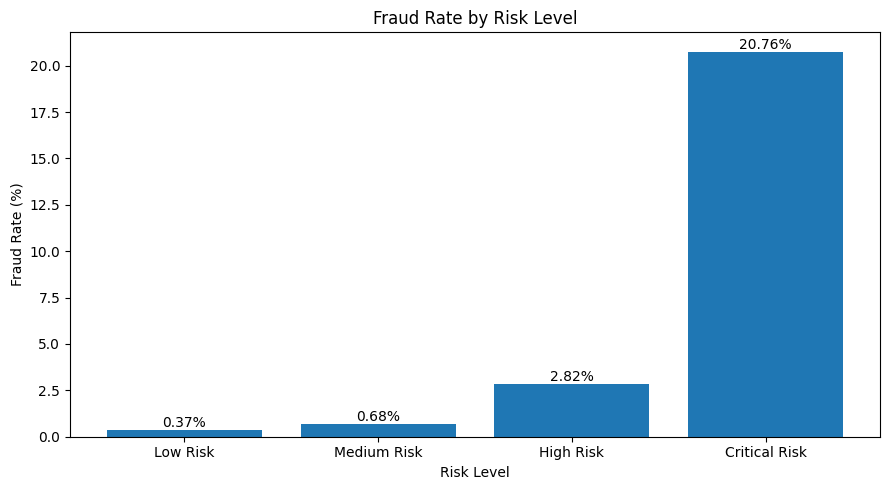

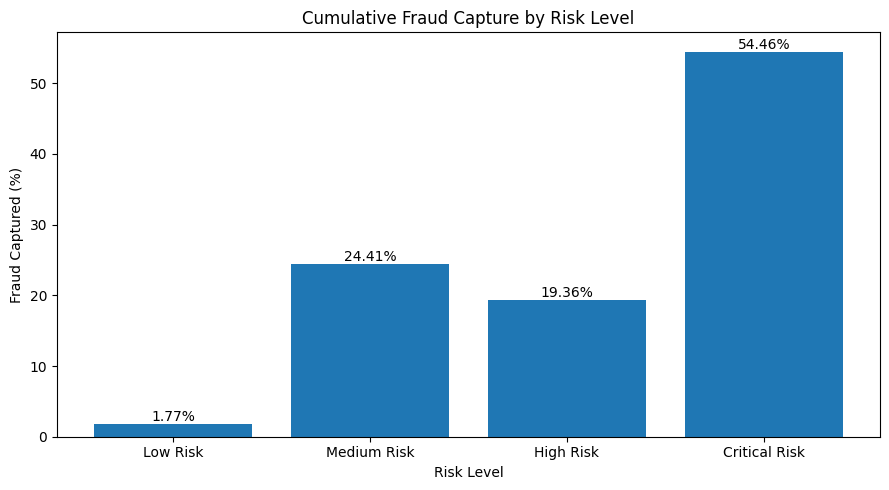

RISK INTELLIGENCE VISUALIZATION COMPLETE


In [114]:
# ============================================================
# RISK INTELLIGENCE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

risk_order = [
    "Low Risk",
    "Medium Risk",
    "High Risk",
    "Critical Risk"
]

# ------------------------------------------------------------
# 1. Fraud Rate by Risk Level
# ------------------------------------------------------------

fraud_rates = (
    risk_analysis
    .reindex(risk_order)["fraud_rate"]
)

plt.figure(figsize=(9, 5))

plt.bar(
    risk_order,
    fraud_rates
)

plt.xlabel("Risk Level")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Risk Level")

for i, value in enumerate(fraud_rates):
    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Fraud Capture by Risk Level
# ------------------------------------------------------------

capture = (
    risk_analysis
    .reindex(risk_order)["fraud_capture_percentage"]
)

plt.figure(figsize=(9, 5))

plt.bar(
    risk_order,
    capture
)

plt.xlabel("Risk Level")
plt.ylabel("Fraud Captured (%)")
plt.title("Cumulative Fraud Capture by Risk Level")

for i, value in enumerate(capture):
    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print("=" * 70)
print("RISK INTELLIGENCE VISUALIZATION COMPLETE")
print("=" * 70)

In [115]:
# ============================================================
# SAVE VALIDATION-STAGE MODEL ARTIFACTS
# ============================================================

import os
import joblib

models_dir = "../models"
os.makedirs(models_dir, exist_ok=True)

print("=" * 70)
print("SAVING MODEL ARTIFACTS")
print("=" * 70)

# ------------------------------------------------------------
# Save Logistic Regression
# ------------------------------------------------------------

joblib.dump(
    lr_model,
    os.path.join(models_dir, "logistic_regression.pkl")
)

# ------------------------------------------------------------
# Save Random Forest
# ------------------------------------------------------------

joblib.dump(
    rf_model,
    os.path.join(models_dir, "random_forest.pkl")
)

# ------------------------------------------------------------
# Save preprocessing pipeline
# ------------------------------------------------------------

joblib.dump(
    preprocessor,
    os.path.join(models_dir, "preprocessor.pkl")
)

# ------------------------------------------------------------
# Save final feature list
# ------------------------------------------------------------

joblib.dump(
    final_features,
    os.path.join(models_dir, "final_features.pkl")
)

# ------------------------------------------------------------
# Save selected thresholds
# ------------------------------------------------------------

joblib.dump(
    lr_threshold,
    os.path.join(models_dir, "lr_threshold.pkl")
)

joblib.dump(
    rf_threshold,
    os.path.join(models_dir, "rf_threshold.pkl")
)

print("\nArtifacts saved successfully:")
print("1. logistic_regression.pkl")
print("2. random_forest.pkl")
print("3. preprocessor.pkl")
print("4. final_features.pkl")
print("5. lr_threshold.pkl")
print("6. rf_threshold.pkl")

print("\nLocation:")
print(os.path.abspath(models_dir))

print("\n" + "=" * 70)
print("MODEL ARTIFACT SAVING COMPLETE")
print("=" * 70)

SAVING MODEL ARTIFACTS

Artifacts saved successfully:
1. logistic_regression.pkl
2. random_forest.pkl
3. preprocessor.pkl
4. final_features.pkl
5. lr_threshold.pkl
6. rf_threshold.pkl

Location:
C:\Users\ANIKET KUMAR\Documents\Financial-Fraud-Detection-System\models

MODEL ARTIFACT SAVING COMPLETE


In [116]:
# ============================================================
# VERIFY SAVED PREPROCESSOR
# ============================================================

import joblib
from pathlib import Path

models_dir = Path("../models")

preprocessor = joblib.load(
    models_dir / "preprocessor.pkl"
)

print("=" * 70)
print("SAVED PREPROCESSOR VERIFICATION")
print("=" * 70)

print("\n=== PREPROCESSOR ===")
print(preprocessor)

print("\n=== TRANSFORMERS ===")

for name, transformer, columns in preprocessor.transformers_:

    print("\nTransformer:", name)
    print("Columns:", list(columns))

    if hasattr(transformer, "transformers_"):

        for sub_name, sub_transformer, sub_columns in transformer.transformers_:

            print("  ", sub_name)
            print("   Columns:", list(sub_columns))

            if hasattr(sub_transformer, "categories_"):
                print(
                    "   Categories:",
                    sub_transformer.categories_
                )

print("\n" + "=" * 70)
print("PREPROCESSOR VERIFICATION COMPLETE")
print("=" * 70)

SAVED PREPROCESSOR VERIFICATION

=== PREPROCESSOR ===
ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['account_age_days', 'credit_score_band',
                                  'kyc_level', 'avg_monthly_spend',
                                  'merchant_risk_score', 'transaction_amount',
                                  'is_international', 'ip_risk_score',
                                  'txn_count_1h', 'txn_count_24h',
                                  'failed_txn_count_24h',
                                  'geo_distanc...
                                  'customer_prev_avg_amount',
                                  'merchant_prev_avg_amount',
                                  'customer_amount_ratio',
                        

In [117]:
from pathlib import Path

data_dir = Path("../data")

print("=" * 70)
print("DATA DIRECTORY")
print("=" * 70)

if data_dir.exists():
    print("\nFiles in data directory:")
    for item in sorted(data_dir.iterdir()):
        print("-", item.name)
else:
    print("\nData directory not found:", data_dir.resolve())

DATA DIRECTORY

Files in data directory:
- .ipynb_checkpoints
- processed
- raw
- transaction_history.json


In [118]:
from pathlib import Path

base = Path("../data")

for folder in ["raw", "processed"]:
    path = base / folder

    print(f"\n===== {folder.upper()} =====")

    if path.exists():
        for file in sorted(path.iterdir()):
            print(file.name)
    else:
        print("Folder not found:", path.resolve())


===== RAW =====
.ipynb_checkpoints
transactions_test.csv
transactions_train.csv

===== PROCESSED =====


In [119]:
import pandas as pd
from pathlib import Path

path = Path("../data/raw/transactions_train.csv")

df = pd.read_csv(path)

print("Dataset shape:", df.shape)

print("\n===== credit_score_band =====")
print(df["credit_score_band"].unique())
print("dtype:", df["credit_score_band"].dtype)

print("\n===== kyc_level =====")
print(df["kyc_level"].unique())
print("dtype:", df["kyc_level"].dtype)

print("\n===== SAMPLE =====")
print(
    df[
        ["credit_score_band", "kyc_level"]
    ].head(10)
)

Dataset shape: (300113, 21)

===== credit_score_band =====
[2 5 1 4 3]
dtype: int64

===== kyc_level =====
[3 2 1]
dtype: int64

===== SAMPLE =====
   credit_score_band  kyc_level
0                  2          3
1                  2          3
2                  5          2
3                  1          1
4                  2          3
5                  2          3
6                  4          1
7                  2          2
8                  5          2
9                  5          2


In [120]:
print(df.columns.tolist())

['transaction_id', 'transaction_time', 'customer_id', 'merchant_id', 'account_age_days', 'credit_score_band', 'kyc_level', 'avg_monthly_spend', 'merchant_risk_score', 'transaction_amount', 'payment_channel', 'device_type', 'is_international', 'ip_risk_score', 'txn_count_1h', 'txn_count_24h', 'failed_txn_count_24h', 'geo_distance_from_last_txn', 'amount_deviation_from_user_mean', 'is_fraud', 'post_auth_risk_score']


In [121]:
import joblib
from pathlib import Path

path = Path("../models/final_features.pkl")

final_features = joblib.load(path)

print("Total features:", len(final_features))

for i, feature in enumerate(final_features, 1):
    print(f"{i:02d}. {feature}")

Total features: 63
01. account_age_days
02. credit_score_band
03. kyc_level
04. avg_monthly_spend
05. merchant_risk_score
06. transaction_amount
07. payment_channel
08. device_type
09. is_international
10. ip_risk_score
11. txn_count_1h
12. txn_count_24h
13. failed_txn_count_24h
14. geo_distance_from_last_txn
15. amount_deviation_from_user_mean
16. hour
17. day_of_week
18. day
19. month
20. is_weekend
21. customer_prev_txn_count
22. merchant_prev_txn_count
23. customer_prev_fraud_count
24. merchant_prev_fraud_count
25. customer_prev_fraud_rate
26. merchant_prev_fraud_rate
27. customer_prev_avg_amount
28. merchant_prev_avg_amount
29. customer_amount_ratio
30. merchant_amount_ratio
31. customer_smoothed_fraud_rate
32. merchant_smoothed_fraud_rate
33. day_of_month
34. is_late_night
35. is_evening
36. amount_to_monthly_spend
37. abs_amount_deviation
38. relative_amount_deviation
39. high_value_transaction
40. txn_velocity_ratio
41. failed_txn_ratio
42. high_velocity_1h
43. high_velocity_24

In [122]:
import pandas as pd
from pathlib import Path

path = Path("../data/raw/transactions_train.csv")

df = pd.read_csv(path)

for col in [
    "customer_smoothed_fraud_rate",
    "merchant_smoothed_fraud_rate"
]:
    print(
        col,
        "exists =", col in df.columns
    )

customer_smoothed_fraud_rate exists = False
merchant_smoothed_fraud_rate exists = False


In [123]:
# ============================================================
# RAW DATA HISTORICAL FEATURE SOURCE CHECK
# ============================================================

import pandas as pd
from pathlib import Path

path = Path("../data/raw/transactions_train.csv")

df = pd.read_csv(path)

print("=" * 70)
print("RAW DATA SOURCE CHECK")
print("=" * 70)

print("\nRows:", len(df))

print("\nFraud rate:")
print(f"{df['is_fraud'].mean():.6f}")
print(f"Fraud rate (%): {df['is_fraud'].mean() * 100:.4f}%")

print("\nRequired raw source columns:")

source_cols = [
    "customer_id",
    "merchant_id",
    "transaction_amount",
    "is_fraud"
]

for col in source_cols:
    print(f"{col}: {col in df.columns}")

print("\n" + "=" * 70)
print("CUSTOMER FRAUD HISTORY SAMPLE")
print("=" * 70)

print(
    df.groupby("customer_id")["is_fraud"]
      .agg(
          transaction_count="count",
          fraud_count="sum",
          fraud_rate="mean"
      )
      .head(10)
)

print("\n" + "=" * 70)
print("MERCHANT FRAUD HISTORY SAMPLE")
print("=" * 70)

print(
    df.groupby("merchant_id")["is_fraud"]
      .agg(
          transaction_count="count",
          fraud_count="sum",
          fraud_rate="mean"
      )
      .head(10)
)

RAW DATA SOURCE CHECK

Rows: 300113

Fraud rate:
0.016231
Fraud rate (%): 1.6231%

Required raw source columns:
customer_id: True
merchant_id: True
transaction_amount: True
is_fraud: True

CUSTOMER FRAUD HISTORY SAMPLE
             transaction_count  fraud_count  fraud_rate
customer_id                                            
0                            6            0    0.000000
1                            7            0    0.000000
2                            4            0    0.000000
3                            9            0    0.000000
4                            3            0    0.000000
5                            3            0    0.000000
6                            7            1    0.142857
7                            7            0    0.000000
8                            6            0    0.000000
9                            7            0    0.000000

MERCHANT FRAUD HISTORY SAMPLE
             transaction_count  fraud_count  fraud_rate
merchant_id           

In [124]:
# ================================================================
# FINAL TEST EVALUATION
# ================================================================

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)


# ------------------------------------------------
# 1. TEST PROBABILITIES
# ------------------------------------------------

lr_test_prob = lr_model.predict_proba(X_test_processed)[:, 1]
rf_test_prob = rf_model.predict_proba(X_test_processed)[:, 1]


# ------------------------------------------------
# 2. USE VALIDATION-SELECTED THRESHOLDS
# ------------------------------------------------

lr_threshold = best_lr_threshold
rf_threshold = best_rf_threshold

lr_test_pred = (lr_test_prob >= lr_threshold).astype(int)
rf_test_pred = (rf_test_prob >= rf_threshold).astype(int)


# ------------------------------------------------
# 3. EVALUATION FUNCTION
# ------------------------------------------------

def evaluate_test_model(name, y_true, y_prob, y_pred, threshold):

    accuracy = accuracy_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_prob)
    pr_auc = average_precision_score(y_true, y_prob)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(f"Operating Threshold : {threshold:.2f}")
    print(f"Accuracy            : {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"ROC-AUC             : {roc_auc:.4f}")
    print(f"PR-AUC              : {pr_auc:.4f}")
    print(f"Precision           : {precision:.4f}")
    print(f"Recall              : {recall:.4f}")
    print(f"F1-Score            : {f1:.4f}")

    print("\nConfusion Matrix")
    print("-" * 40)

    print(f"True Negatives      : {tn:,}")
    print(f"False Positives     : {fp:,}")
    print(f"False Negatives     : {fn:,}")
    print(f"True Positives      : {tp:,}")

    print("\nClassification Report")
    print("-" * 40)

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=["Legitimate", "Fraud"],
            zero_division=0
        )
    )

    return {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "False_Positives": fp,
        "False_Negatives": fn,
        "True_Positives": tp,
        "True_Negatives": tn
    }


# ------------------------------------------------
# 4. LOGISTIC REGRESSION
# ------------------------------------------------

lr_test_results = evaluate_test_model(
    "LOGISTIC REGRESSION",
    y_test,
    lr_test_prob,
    lr_test_pred,
    lr_threshold
)


# ------------------------------------------------
# 5. RANDOM FOREST
# ------------------------------------------------

rf_test_results = evaluate_test_model(
    "RANDOM FOREST",
    y_test,
    rf_test_prob,
    rf_test_pred,
    rf_threshold
)


# ------------------------------------------------
# 6. FINAL COMPARISON
# ------------------------------------------------

final_test_results = pd.DataFrame([
    lr_test_results,
    rf_test_results
])

print("\n" + "=" * 70)
print("FINAL TEST MODEL COMPARISON")
print("=" * 70)

display(final_test_results)

FINAL TEST EVALUATION

LOGISTIC REGRESSION
Operating Threshold : 0.90
Accuracy            : 0.9763 (97.63%)
ROC-AUC             : 0.8419
PR-AUC              : 0.2867
Precision           : 0.3871
Recall              : 0.3293
F1-Score            : 0.3559

Confusion Matrix
----------------------------------------
True Negatives      : 96,870
False Positives     : 1,034
False Negatives     : 1,330
True Positives      : 653

Classification Report
----------------------------------------
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99     97904
       Fraud       0.39      0.33      0.36      1983

    accuracy                           0.98     99887
   macro avg       0.69      0.66      0.67     99887
weighted avg       0.97      0.98      0.98     99887


RANDOM FOREST
Operating Threshold : 0.55
Accuracy            : 0.9803 (98.03%)
ROC-AUC             : 0.8122
PR-AUC              : 0.2706
Precision           : 0.6735
Recall             

,Model,Threshold,Accuracy,ROC_AUC,PR_AUC,Precision,Recall,F1_Score,False_Positives,False_Negatives,True_Positives,True_Negatives
0,LOGISTIC REGRESSION,0.90,0.976333,0.841937,0.286745,0.387078,0.329299,0.355858,1034,1330,653,96870
1,RANDOM FOREST,0.55,0.980318,0.812226,0.270584,0.673469,0.016641,0.032480,16,1950,33,97888
